# 08 · Robustness, controls and the one-time test unlock (Day 6: Stage 11)
**Microstructure Alpha · every choice was frozen in notebooks 04–07 · test days D7–D8 are opened exactly once, in Part 4**

| Part | Content | Data |
|---|---|---|
| 0 | Protocol hash check; re-create the frozen choices (signal, θ_A, θ_B, Hawkes parameters) and write them to `protocol/frozen_choices.json` with a hash | D1–D6 |
| 1 | **Signal diagnostics**: collinearity, calibration (why the D6 R² is negative), leave-one-day-out with feature variants, IC-vs-latency curve with block-bootstrap CIs, future-shift placebo, shuffle null, data-handling sensitivity | D1–D6 |
| 2 | **Track A controls**: last-second, random delay, **matched delay** (the timed strategy's own delays, assigned at random), stale signal, reversed signal, price-only rule; θ_A grid extended past 2.0 (diagnostic only); leave-one-day-out θ choice | D1–D6 |
| 3 | **Track B surface** on the selection day: θ_B × latency | D6 |
| 4 | **TEST UNLOCK** (ledger in `protocol/test_unlock.json`): H1–H7, signal, Track A (frozen θ_A plus every control from Part 2), Track B, Track C, rolling walk-forward over all 8 days (transparency only) | **D7–D8** |
| 5 | Sensitivity surfaces (cost × latency, θ × latency) and deflated Sharpe ratios | D6, D7–D8 |
| 6 | Scorecard: development → selection → test for every claim | all |

**What is fixed before the unlock (written now):**
- **Frozen choices:** linear signal (coefficients fit on D1–D5), θ_A = argmax of the notebook-07 calibration, θ_B likewise, headline fees and latency 130 ms. Nothing in Parts 1–3 can change them; the extended θ grid and the surfaces are diagnostics.
- **Track A, the decisive control:** *matched delay* takes the send delays the timed strategy actually chose and gives them to children at random. Same delay distribution, no signal information. **Signal value = matched-delay shortfall − timed shortfall.** If its 95% CI includes 0, the Track A saving is a timing artefact rather than alpha.
- **Test-day criteria** (two days, so "every day" means both):
  - **H1:** β > 0 with HAC t > 1.96 on both test days, and OFI R² > TI R² on both.
  - **H2:** the pooled test-day slope CI excludes 0.
  - **H3:** some horizon significant after Romano–Wolf (fit on D1–D6).
  - **H4:** both event clocks beat the clock window (DM p < 0.05).
  - **H5:** some candidate beats both level-1 OFI and the microprice (DM, Holm-adjusted 5%).
  - **H6:** on each test day 0 < γ < 1 and the propagator decay β > 0 (point estimates; two days cannot give a t-interval).
  - **H7:** Holm-adjusted p < 0.05 at some horizon.
- **Funding** is not modelled (no funding-rate data).

**Runtime:** about 45–90 minutes. **Memory:** close other kernels first; peak about 2.5 GB.

In [1]:
# ===================== CONFIG =====================
from pathlib import Path
OUT_DIR         = Path(r"C:\microalpha_proj\microoutput")
FEE_MAKER_BP    = 2.0       # same headline tier as notebook 07 (must be a protocol grid point)
FEE_TAKER_BP    = 5.0
UNLOCK_TEST     = True      # Part 4 opens D7–D8 once; a ledger records the first unlock
# notebook-07 reference values from your run (reproduction checks only; they never change a choice)
REF_COEF        = {'const': -0.0328, 'ofi1_bin': 0.00726, 'ofi1_1s': 0.00071, 'ti_1s': 0.0004, 'qi': 0.91165,
                   'hawkes_net': 0.04743, 'hawkes_tot': 0.00417, 'micro': 0.77799}
REF_TA_SAVING   = 0.2050    # Track A saving on D6 at L = 130 ms (bp)
# Track A / B settings: identical to notebook 07
N_PARENTS_DEV, N_PARENTS_SEL, N_PARENTS_TEST = 60, 300, 300      # test: per test day
PARENT_ETH, PARENT_MIN, SLOT_S = 50, 10, 30
THETA_A_GRID    = [0.1, 0.25, 0.5, 1.0, 2.0, 1e9]
THETA_A_EXT     = [3.0, 5.0, 8.0, 13.0]                 # diagnostic only
THETA_B_GRID    = [0.25, 0.5, 1.0, 2.0, 1e9]
MM_Q_ETH, MM_INV_MAX_ETH = 1.0, 10.0
STALE_S         = 60        # stale-signal placebo: the forecast from 60 s earlier
PRICE_X_TICKS   = [2.0, 5.0]  # price-only control: send early once the mid has moved this much in our favour
PERM_REPS, BOOT_REPS, NULL_REPS = 1000, 1000, 200
STRICT          = True
# ==================================================

In [2]:
import sys, os, time, math, gc, json, hashlib, datetime, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
import ma_lib
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)
P = ma_lib.load_protocol(OUT_DIR)
PRO, REP, EVT, FEA, BOOK = OUT_DIR / 'protocol', OUT_DIR / 'reports', OUT_DIR / 'events', OUT_DIR / 'features', OUT_DIR / 'book'
PHASH = hashlib.sha256((PRO / 'protocol.json').read_text(encoding='utf-8').encode('utf-8')).hexdigest()
DEV = P['data_split']['development']; SEL = P['data_split']['selection'][0]; TEST = P['data_split']['test']; PRE = DEV + [SEL]
LAT_GRID = P['grid']['latency_grid_ms']; FEE_GRID = P['costs']['fee_grid_bp']; SEED = P['inference']['seed']
EMB_MIN = P['purge_embargo']['embargo_minutes']; BLOCK_MIN = P['inference']['bootstrap']['block_minutes']
HORIZONS = P['target']['horizons_s']; BIN_S = P['grid']['bin_ms'] / 1000
assert FEE_MAKER_BP in FEE_GRID['maker'] and FEE_TAKER_BP in FEE_GRID['taker'], 'headline fees must be pre-registered grid points'
def day_ok(d):
    return all(p.exists() for p in (FEA / 'ex' / f'feat_ex_{d}.parquet', FEA / 'rx' / f'feat_rx_{d}.parquet', EVT / f'taker_orders_{d}.parquet', EVT / d, BOOK / d))
miss = [d for d in PRE if not day_ok(d)]
if STRICT and miss: raise RuntimeError(f'missing pre-test inputs for {miss}')
if UNLOCK_TEST and [d for d in TEST if not day_ok(d)]: raise RuntimeError('test-day inputs are missing (features, events, taker orders or book)')
print(f'protocol sha256 {PHASH} (verified) | dev {DEV} | selection {SEL} | test {TEST} | unlock: {UNLOCK_TEST}')
def emb_mask(t_end, day):
    t0 = pd.Timestamp(day).value // 10**6; return (t_end >= t0 + EMB_MIN * 60_000) & (t_end <= t0 + 86_400_000 - EMB_MIN * 60_000)
def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); adj = np.empty_like(p); run = 0.0
    for r, i in enumerate(o): run = max(run, min(1.0, (len(p) - r) * p[i])); adj[i] = run
    return adj
def read_csv_safe(p):
    try: return pd.read_csv(p)
    except (pd.errors.EmptyDataError, FileNotFoundError): return pd.DataFrame()
def boot_ci(x, reps=BOOT_REPS, seed=SEED):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    if len(x) < 2: return np.nan, np.nan
    r = np.random.default_rng(seed); b = x[r.integers(0, len(x), (reps, len(x)))].mean(1); return tuple(np.percentile(b, [2.5, 97.5]))
QW = read_csv_safe(REP / '02_quality_windows.csv')
BAD_HOURS = set() if QW.empty else {(str(r.date), int(r.hour)) for r in QW.itertuples() if r.reason in ('resync_gap', 'invalid_book')}
print(f'hours containing a resync or invalid book (excluded in the data-handling checks): {len(BAD_HOURS)}')

protocol sha256 0224381a70665d880a38c72f35f2b250fa3c97b7281b56e817d71372b22234af (verified) | dev ['2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11'] | selection 2026-09-12 | test ['2026-09-13', '2026-09-14'] | unlock: True
hours containing a resync or invalid book (excluded in the data-handling checks): 12


## 0 · Re-create and freeze the choices
Nothing here is tuned: the notebook-07 rules are re-applied to the saved notebook-07 tables, and the signal is refit exactly as in notebook 07 (same data, same code, deterministic). Its coefficients are compared with your notebook-07 printout. The choices are written to `protocol/frozen_choices.json`. If that file already exists with different content, the notebook stops.

In [3]:
r2_07 = read_csv_safe(REP / '07_deep_vs_linear.csv'); dm_07 = read_csv_safe(REP / '07_deep_vs_linear_dm.csv'); accepted = None
for mname in ('lightgbm', 'cnn'):
    row = dm_07[(dm_07.model == mname) & (dm_07.target_s == 1)] if len(dm_07) else pd.DataFrame()
    if len(row) and row.p_holm.iloc[0] < 0.05:
        s_m = r2_07[(r2_07.model == mname) & (r2_07.target_s == 1)].oos_r2_selection_day.iloc[0]; s_r = r2_07[(r2_07.model == 'ridge_window') & (r2_07.target_s == 1)].oos_r2_selection_day.iloc[0]
        if s_m > s_r and (accepted is None or s_m > r2_07[(r2_07.model == accepted) & (r2_07.target_s == 1)].oos_r2_selection_day.iloc[0]): accepted = mname
SIGNAL_MODEL = 'lightgbm' if accepted == 'lightgbm' else 'linear'
if SIGNAL_MODEL != 'linear': raise RuntimeError('notebook 07 accepted LightGBM; this notebook re-creates only the linear signal')
cs07 = pd.read_csv(REP / '07_trackA_calibration.csv').groupby('theta').saving_bp.mean(); THETA_A = float(cs07.idxmax()) if cs07.max() > 0 else 1e9
cb07 = pd.read_csv(REP / '07_trackB_calibration.csv').groupby('theta').gross_ticks.mean(); THETA_B = float(cb07.idxmax())
hh = pd.read_csv(REP / '06_hawkes_hourly.csv'); hh = hh[hh.date.isin(DEV)]
HK_BETA = float(hh.beta.mode().iloc[0]); HK_A = np.array([[hh.A_bb.median(), hh.A_bs.median()], [hh.A_sb.median(), hh.A_ss.median()]])
print(f'signal model: {SIGNAL_MODEL} (complex model accepted in 07: {accepted or "none"}) | θ_A = {THETA_A} | θ_B = {THETA_B} | Hawkes β = {HK_BETA}, A = {np.round(HK_A, 3).tolist()}')
if THETA_A == max(THETA_A_GRID[:-1]): print('note: θ_A sits at the edge of the notebook-07 grid (Part 2 extends the grid as a diagnostic; the frozen value does not change)')

signal model: linear (complex model accepted in 07: none) | θ_A = 2.0 | θ_B = 1.0 | Hawkes β = 100.0, A = [[0.355, 0.035], [0.031, 0.355]]
note: θ_A sits at the edge of the notebook-07 grid (Part 2 extends the grid as a diagnostic; the frozen value does not change)


In [4]:
RCOLS = ['t_end', 'valid', 'bp1', 'ap1', 'bq1', 'aq1', 'ofi1', 'v_buy', 'v_sell', 'v_buy_x', 'v_sell_x', 'rv_halfticks2']
def order_times_R(d):
    u_, R_ = [], []
    for hr in range(24):
        f = EVT / d / f'events_{d}_{hr:02d}.parquet'
        if f.exists(): e = pd.read_parquet(f, columns=['u', 'R']); u_.append(e.u.to_numpy()); R_.append(e.R.to_numpy() // 1_000_000)
    u_, R_ = np.concatenate(u_), np.concatenate(R_)
    o = pd.read_parquet(EVT / f'taker_orders_{d}.parquet', columns=['u_post', 'sign', 'usable']); o = o[o.usable]
    j = np.clip(np.searchsorted(u_, o.u_post.to_numpy()), 0, len(u_) - 1); ok = u_[j] == o.u_post.to_numpy()
    t = R_[j][ok]; ty = (o.sign.to_numpy()[ok] < 0).astype(np.int64); oo = np.argsort(t, kind='stable'); return t[oo], ty[oo]
def rx_features(d):                                       # identical to notebook 07, plus columns used only by the diagnostics
    g = pd.read_parquet(FEA / 'rx' / f'feat_rx_{d}.parquet', columns=RCOLS); d0 = pd.Timestamp(d).value // 10**6
    o1 = g.ofi1.to_numpy(float) / 1000; ti = (g.v_buy - g.v_sell).to_numpy(float) / 1000; tix = (g.v_buy_x - g.v_sell_x).to_numpy(float) / 1000
    roll = lambda x: pd.Series(x).rolling(10, min_periods=1).sum().to_numpy()
    bq, aq = g.bq1.to_numpy(float), g.aq1.to_numpy(float); qi = (bq - aq) / np.where(bq + aq > 0, bq + aq, np.nan)
    tm, ty = order_times_R(d)
    E = ma_lib._hawkes_excitation_grid((tm - d0) / 1000.0, ty, (g.t_end.to_numpy() - d0) / 1000.0 + 1e-9, HK_A, HK_BETA, 2)
    X = np.c_[o1, roll(o1), roll(ti), np.nan_to_num(qi), E[:, 0] - E[:, 1], E[:, 0] + E[:, 1]]
    m2 = (g.bp1 + g.ap1).to_numpy(float); y = np.full(len(m2), np.nan); y[:-10] = (m2[10:] - m2[:-10]) / 2.0
    v = g.valid.to_numpy(); fut = np.r_[v[10:], np.zeros(10, bool)]
    mask = v & fut & np.isfinite(qi) & emb_mask(g.t_end.to_numpy(), d)
    fast = g.rv_halfticks2.to_numpy(float) >= 64            # approx.: the bin holds at least one 4-tick move
    fast_next = pd.Series(fast[::-1].astype(float)).rolling(10, min_periods=1).max().to_numpy()[::-1]
    fast_next = np.r_[fast_next[1:], 0.0] > 0                # any fast bin in (t, t + 1 s]
    hour = np.clip((g.t_end.to_numpy() - d0 - 1) // 3_600_000, 0, 23).astype(np.int8)
    return dict(t=g.t_end.to_numpy(), X=X, tix=roll(tix), qi=np.nan_to_num(qi), y=y, mask=mask, valid=v, m2=m2, fast_next=fast_next, hour=hour)
RX = {}; t0 = time.time()
for d in PRE:
    RX[d] = rx_features(d); print(f'{d}: received-clock features ({RX[d]["mask"].sum():,} usable bins, {time.time()-t0:.0f}s)')
FEATS = ['ofi1_bin', 'ofi1_1s', 'ti_1s', 'qi', 'hawkes_net', 'hawkes_tot', 'micro']
def micro_fit(days):
    q = np.concatenate([RX[d]['qi'][RX[d]['mask']] for d in days]); yy = np.concatenate([RX[d]['y'][RX[d]['mask']] for d in days])
    e = np.unique(np.quantile(q, np.linspace(0, 1, 11))); e[0], e[-1] = -np.inf, np.inf
    b = np.digitize(q, e[1:-1]); mm = np.bincount(b, weights=yy, minlength=len(e) - 1) / np.maximum(np.bincount(b, minlength=len(e) - 1), 1)
    return e, mm
EDGES, MMAP = micro_fit(DEV)
def design(d, e=None, mm=None):
    e = EDGES if e is None else e; mm = MMAP if mm is None else mm
    return np.c_[RX[d]['X'], mm[np.digitize(RX[d]['qi'], e[1:-1])]]
ytr = np.concatenate([RX[d]['y'][RX[d]['mask']] for d in DEV]); Xtr = np.vstack([design(d)[RX[d]['mask']] for d in DEV])
COEF = np.linalg.lstsq(np.c_[np.ones(len(ytr)), Xtr], ytr, rcond=None)[0]
predict_sig = lambda X: COEF[0] + X @ COEF[1:]
for d in PRE: RX[d]['f'] = np.where(RX[d]['valid'], predict_sig(design(d)), np.nan)
cf = dict(zip(['const'] + FEATS, COEF)); dif = max(abs(cf[k] - REF_COEF[k]) for k in REF_COEF)
print('signal coefficients:', {k: round(float(v), 5) for k, v in cf.items()})
print(f'max |difference| vs your notebook-07 coefficients: {dif:.5f} ' + ('(reproduced)' if dif < 5e-4 else '— NOT reproduced: check that notebook 07 ran on the same inputs'))
FROZEN = dict(signal_model=SIGNAL_MODEL, features=FEATS, coef=[float(c) for c in COEF], micro_edges=[float(x) for x in EDGES], micro_map=[float(x) for x in MMAP],
              theta_A=THETA_A, theta_B=THETA_B, hawkes_beta=HK_BETA, hawkes_A=HK_A.tolist(), fee_maker_bp=FEE_MAKER_BP, fee_taker_bp=FEE_TAKER_BP, headline_latency_ms=130,
              parent=dict(eth=PARENT_ETH, minutes=PARENT_MIN, slot_s=SLOT_S), mm=dict(q_eth=MM_Q_ETH, inv_max_eth=MM_INV_MAX_ETH),
              controls=dict(stale_s=STALE_S, price_x_ticks=PRICE_X_TICKS), protocol_sha256=PHASH)
blob = json.dumps(FROZEN, sort_keys=True, indent=2); fpath = PRO / 'frozen_choices.json'
if fpath.exists() and fpath.read_text(encoding='utf-8') != blob:
    raise RuntimeError('frozen_choices.json exists with different content: a choice changed after the freeze. Investigate before going on.')
fpath.write_text(blob, encoding='utf-8'); FHASH = hashlib.sha256(blob.encode('utf-8')).hexdigest(); fpath.with_suffix('.sha256').write_text(FHASH, encoding='utf-8')
print('frozen choices written:', fpath, '| sha256', FHASH)

2026-09-07: received-clock features (850,385 usable bins, 3s)
2026-09-08: received-clock features (843,484 usable bins, 4s)
2026-09-09: received-clock features (848,643 usable bins, 5s)
2026-09-10: received-clock features (833,148 usable bins, 6s)
2026-09-11: received-clock features (845,836 usable bins, 7s)
2026-09-12: received-clock features (816,311 usable bins, 8s)
signal coefficients: {'const': -0.0328, 'ofi1_bin': 0.00726, 'ofi1_1s': 0.00071, 'ti_1s': 0.0004, 'qi': 0.91165, 'hawkes_net': 0.04743, 'hawkes_tot': 0.00417, 'micro': 0.77799}
max |difference| vs your notebook-07 coefficients: 0.00000 (reproduced)
frozen choices written: C:\microalpha_proj\microoutput\protocol\frozen_choices.json | sha256 c540fa09a5111069488bcebca00cae46a03d591ffce33a93abac819a22ab762e


## 1 · Signal diagnostics (D1–D6, before the unlock)
**Why can the D6 R² be negative while the IC is clearly positive?** R² is measured against the zero forecast, so it punishes a forecast that ranks moves correctly but is **too large** (calibration slope b < 1) or **biased** (a constant offset). The calibration table splits these apart. *R² oracle* refits a and b on that same day; it is the most a rescaled forecast could have reached, shown for diagnosis only.

In [5]:
n = len(ytr); G = Xtr.T @ Xtr / n; mu_ = Xtr.mean(0); Cv = G - np.outer(mu_, mu_); sd_ = np.sqrt(np.diag(Cv)); Corr = Cv / np.outer(sd_, sd_)
VIF = np.diag(np.linalg.inv(Corr)); COND = np.linalg.cond(Corr)
print(f'feature correlation matrix (D1–D5): condition number {COND:.1f}'); display(pd.DataFrame(Corr, index=FEATS, columns=FEATS).round(3))
display(pd.DataFrame({'VIF': VIF, 'coef': COEF[1:], 'coef × sd (ticks per 1 sd)': COEF[1:] * sd_}, index=FEATS).round(4))
del Xtr; _ = gc.collect()
def calib(y, f):
    ok = np.isfinite(y) & np.isfinite(f); y, f = y[ok], f[ok]
    b, a = np.polyfit(f, y, 1); e = y - a - b * f
    return dict(n=len(y), r2=ma_lib.oos_r2(y, f), r2_oracle_rescaled=1 - (e @ e) / (y @ y), ic=np.corrcoef(f, y)[0, 1], calib_slope=b, calib_intercept=a,
                mean_f=f.mean(), mean_y=y.mean(), sd_f=f.std(), sd_y=y.std())
cal_rows = [dict(date=d, sample='in-sample (fit days)' if d in DEV else 'selection day (OOS)', **calib(RX[d]['y'][RX[d]['mask']], RX[d]['f'][RX[d]['mask']])) for d in PRE]
CAL = pd.DataFrame(cal_rows).set_index('date'); display(CAL.round(5))
c6 = CAL.loc[SEL]
diag = ('ranking information is intact (IC > 0) but the forecast is mis-scaled: ' + f'slope {c6.calib_slope:.2f} (1 = well scaled), intercept {c6.calib_intercept:.4f} ticks') if c6.ic > 0 and c6.r2 < 0 else 'no scale/ranking split needed'
print('D6 diagnosis:', diag)
CAL.to_csv(REP / '08_signal_calibration.csv')

feature correlation matrix (D1–D5): condition number 45.2


,ofi1_bin,ofi1_1s,ti_1s,qi,hawkes_net,hawkes_tot,micro
ofi1_bin,1.000,0.353,0.094,0.243,0.269,0.000,0.259
ofi1_1s,0.353,1.000,0.261,0.396,0.104,0.003,0.394
ti_1s,0.094,0.261,1.000,0.053,0.047,0.013,0.052
qi,0.243,0.396,0.053,1.000,0.102,-0.002,0.946
hawkes_net,0.269,0.104,0.047,0.102,1.000,0.029,0.111
hawkes_tot,0.000,0.003,0.013,-0.002,0.029,1.000,-0.002
micro,0.259,0.394,0.052,0.946,0.111,-0.002,1.000


,VIF,coef,coef × sd (ticks per 1 sd)
ofi1_bin,1.2390,0.0073,0.7982
ofi1_1s,1.3816,0.0007,0.3058
ti_1s,1.0775,0.0004,0.0639
qi,9.5215,0.9117,0.5547
hawkes_net,1.0816,0.0474,0.5586
hawkes_tot,1.0011,0.0042,0.0914
micro,9.5673,0.7780,3.2147


,sample,n,r2,r2_oracle_rescaled,ic,calib_slope,calib_intercept,mean_f,mean_y,sd_f,sd_y
date,,,,,,,,,,,
2026-09-07,in-sample (fit days),850385,0.05549,0.05692,0.23856,0.87066,-0.17638,0.17076,-0.02771,4.16653,15.20613
2026-09-08,in-sample (fit days),843484,0.05792,0.05801,0.24086,0.96425,0.06253,-0.08468,-0.01913,4.21250,16.86459
2026-09-09,in-sample (fit days),848643,0.05954,0.05956,0.24404,0.98332,-0.02368,-0.00103,-0.02470,4.37647,17.63410
2026-09-10,in-sample (fit days),833148,0.05286,0.05298,0.23017,0.95449,0.00455,-0.03226,-0.02624,4.41699,18.31675
2026-09-11,in-sample (fit days),845836,0.02495,0.02582,0.16065,1.22176,0.16269,-0.04832,0.10365,4.31667,32.82824
2026-09-12,selection day (OOS),816311,-0.00691,0.02474,0.15729,0.46925,0.00357,0.02836,0.01687,3.44515,10.27797


D6 diagnosis: ranking information is intact (IC > 0) but the forecast is mis-scaled: slope 0.47 (1 = well scaled), intercept 0.0036 ticks


**Leave-one-day-out over D1–D6 with feature variants.** Each day is predicted by a model fit on the other five (microprice map refit too). The variants test the collinear pair (queue imbalance and microprice) and the RPI-sensitive input (`full_ti_x` swaps trade imbalance for the version without RPI-candidate trades).

held-out 2026-09-07 done (4s)
held-out 2026-09-08 done (8s)
held-out 2026-09-09 done (12s)
held-out 2026-09-10 done (15s)
held-out 2026-09-11 done (19s)
held-out 2026-09-12 done (23s)
leave-one-day-out OOS R² (rows: held-out day):


variant,full,no_micro,no_qi,qi_only,micro_only,ofi_ti_only,no_hawkes,full_ti_x
date,,,,,,,,
2026-09-07,0.05572,0.05235,0.05559,0.04745,0.05156,0.02054,0.05530,0.05573
2026-09-08,0.05689,0.05362,0.05664,0.05073,0.05440,0.01882,0.05663,0.05691
2026-09-09,0.05864,0.05517,0.05840,0.05164,0.05545,0.01851,0.05838,0.05864
2026-09-10,0.05245,0.04969,0.05224,0.04537,0.04851,0.01834,0.05178,0.05245
2026-09-11,0.02317,0.02180,0.02312,0.01919,0.02090,0.00827,0.02237,0.02317
2026-09-12,-0.00691,-0.01624,-0.00502,-0.03107,-0.01609,0.00963,-0.00803,-0.00691


leave-one-day-out IC:


variant,full,no_micro,no_qi,qi_only,micro_only,ofi_ti_only,no_hawkes,full_ti_x
date,,,,,,,,
2026-09-07,0.2376,0.2300,0.2374,0.2194,0.2291,0.1434,0.2367,0.2377
2026-09-08,0.2386,0.2316,0.2381,0.2257,0.2336,0.1377,0.2380,0.2386
2026-09-09,0.2423,0.2350,0.2418,0.2289,0.2366,0.1402,0.2418,0.2423
2026-09-10,0.2290,0.2230,0.2286,0.2136,0.2204,0.1360,0.2276,0.2290
2026-09-11,0.1583,0.1542,0.1580,0.1454,0.1507,0.0962,0.1557,0.1583
2026-09-12,0.1573,0.1468,0.1582,0.1350,0.1484,0.1018,0.1553,0.1573


calibration slope (full model):


date,2026-09-07,2026-09-08,2026-09-09,2026-09-10,2026-09-11,2026-09-12
calib_slope,0.911,1.018,1.036,1.008,1.375,0.469


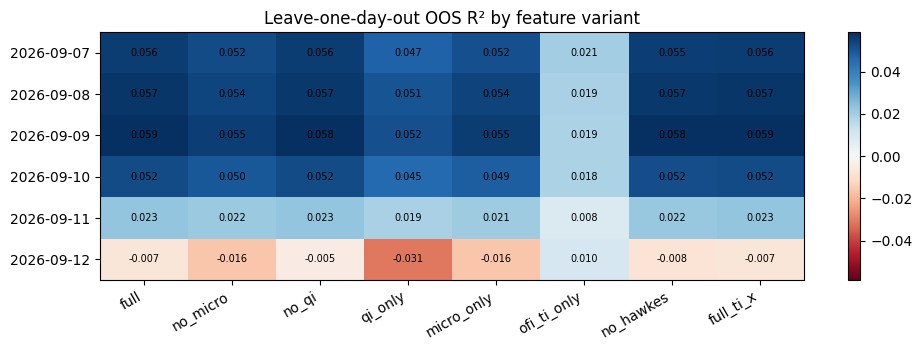

In [6]:
VAR = {'full': [0, 1, 2, 3, 4, 5, 6], 'no_micro': [0, 1, 2, 3, 4, 5], 'no_qi': [0, 1, 2, 4, 5, 6], 'qi_only': [3], 'micro_only': [6],
       'ofi_ti_only': [0, 1, 2], 'no_hawkes': [0, 1, 2, 3, 6], 'full_ti_x': [0, 1, 7, 3, 4, 5, 6]}
def design8(d, e, mm): return np.c_[design(d, e, mm), RX[d]['tix']]          # column 7 = trade imbalance without RPI candidates
lodo = []; t0 = time.time()
for held in PRE:
    tr_days = [d for d in PRE if d != held]; e, mm = micro_fit(tr_days)
    acc = ma_lib.GramAcc(9)
    for d in tr_days:
        Z = design8(d, e, mm)[RX[d]['mask']]; acc.add(np.c_[np.ones(len(Z)), Z], RX[d]['y'][RX[d]['mask']])
    Zh = design8(held, e, mm); m = RX[held]['mask']; yh = RX[held]['y'][m]
    for v, cols in VAR.items():
        idx = [0] + [c + 1 for c in cols]; b = np.linalg.solve(acc.G[np.ix_(idx, idx)], acc.gy[idx])
        fh = b[0] + Zh[:, cols] @ b[1:]
        if v == 'full': RX[held]['f_lodo'] = np.where(RX[held]['valid'], fh, np.nan)
        lodo.append(dict(date=held, variant=v, **{k: calib(yh, fh[m])[k] for k in ('r2', 'ic', 'calib_slope')}))
    print(f'held-out {held} done ({time.time()-t0:.0f}s)')
LODO = pd.DataFrame(lodo)
print('leave-one-day-out OOS R² (rows: held-out day):'); display(LODO.pivot(index='date', columns='variant', values='r2')[list(VAR)].round(5))
print('leave-one-day-out IC:'); display(LODO.pivot(index='date', columns='variant', values='ic')[list(VAR)].round(4))
print('calibration slope (full model):'); display(LODO[LODO.variant == 'full'].set_index('date').calib_slope.round(3).to_frame().T)
LODO.to_csv(REP / '08_signal_lodo.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 3.6)); M = LODO.pivot(index='date', columns='variant', values='r2')[list(VAR)]
im = ax.imshow(M.to_numpy(), cmap='RdBu', vmin=-np.nanmax(np.abs(M.to_numpy())), vmax=np.nanmax(np.abs(M.to_numpy())), aspect='auto')
ax.set_xticks(range(len(VAR))); ax.set_xticklabels(list(VAR), rotation=30, ha='right'); ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index)
for i in range(M.shape[0]):
    for j in range(M.shape[1]): ax.text(j, i, f'{M.iloc[i, j]:.3f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); ax.set_title('Leave-one-day-out OOS R² by feature variant'); plt.tight_layout(); fig.savefig(REP / '08_signal_lodo.png', dpi=110); plt.show()

**IC vs latency, future-shift placebo and shuffle null.** IC(L) correlates the forecast known at local time *t* with the exchange-time mid change over (t + L, t + L + 1 s]. CIs come from a 5-minute block bootstrap.
- **Future-shift placebo:** the same correlation with moves 2 s to 5 min ahead. It should fall to about 0; an IC that stays high far ahead would mean a leak or a common trend.
- **Shuffle null:** the forecast is circularly shifted against the target by at least 10 minutes.
- **Alpha half-life** is the first latency where IC ≤ IC(0)/2. If that never happens within 1 s, the report gives IC(1000)/IC(0) with its CI instead of "inf".
- **Resolution:** the exchange grid is 100 ms, so IC moves in 100 ms steps.

D6 uses the frozen forecast; development days use their leave-one-day-out forecasts, so every point is out of sample.

,kind,offset_ms,ic_D6,ci_lo_D6,ci_hi_D6,ic_dev_lodo,ci_lo_dev_lodo,ci_hi_dev_lodo
0,past 1 s (descriptive),-1000,0.2311,0.2211,0.2416,0.3215,0.3008,0.3418
1,latency,0,0.1306,0.1204,0.1407,0.1508,0.1379,0.1632
2,latency,50,0.1214,0.1114,0.1314,0.1330,0.1213,0.1444
3,latency,100,0.1214,0.1114,0.1314,0.1330,0.1213,0.1444
4,latency,130,0.1140,0.1040,0.1237,0.1200,0.1089,0.1301
5,latency,200,0.1140,0.1040,0.1237,0.1200,0.1089,0.1301
6,latency,250,0.1081,0.0985,0.1179,0.1089,0.0988,0.1185
7,latency,300,0.1081,0.0985,0.1179,0.1089,0.0988,0.1185
8,latency,400,0.1027,0.0931,0.1124,0.0995,0.0900,0.1084
9,latency,500,0.0979,0.0883,0.1075,0.0913,0.0823,0.0997


shuffle null 95th pct |IC|: D6 0.0067, dev 0.0026 | alpha half-life: D6 > 1000 ms (IC(1 s)/IC(0) = 0.63, CI 0.56–0.69); dev 750 ms
future-shift placebo (D6): moves ≥ 30 s ahead have |IC| ≤ 0.0050 vs shuffle-null 95th pct 0.0067 → collapses
future-shift placebo (dev): moves ≥ 30 s ahead have |IC| ≤ 0.0014 vs shuffle-null 95th pct 0.0026 → collapses


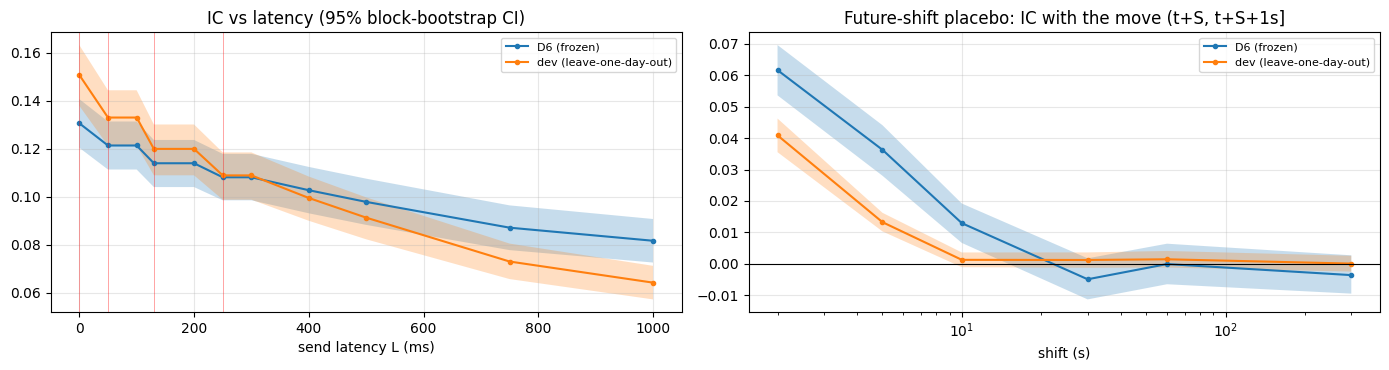

In [7]:
GE = {}
def ex_mid(d):
    if d not in GE:
        g = pd.read_parquet(FEA / 'ex' / f'feat_ex_{d}.parquet', columns=['t_end', 'valid', 'bp1', 'ap1'])
        GE[d] = (g.t_end.to_numpy(), (g.bp1 + g.ap1).to_numpy(float) / 2, g.valid.to_numpy())
    return GE[d]
def mid_ex(d, t):
    te, me, ve = ex_mid(d); i = np.clip(np.searchsorted(te, t, side='left'), 0, len(te) - 1); return me[i], ve[i]
LAGS = [0, 50, 100, 130, 200, 250, 300, 400, 500, 750, 1000]; SHIFTS = [2_000, 5_000, 10_000, 30_000, 60_000, 300_000]
def ic_table(days, key, seed=SEED):
    rows = []
    for L in [-1000] + LAGS + SHIFTS:
        F, Yv, B = [], [], []
        for i, d in enumerate(days):
            m = RX[d]['mask'] & np.isfinite(RX[d][key]); tt = RX[d]['t'][m]; ff = RX[d][key][m]
            a, va = mid_ex(d, tt + L); b, vb = mid_ex(d, tt + L + 1000); ok = va & vb
            F.append(ff[ok]); Yv.append((b - a)[ok]); B.append(i * 10**6 + ma_lib.block_ids(tt[ok], BLOCK_MIN))
        ic, lo, hi = ma_lib.ic_ci(np.concatenate(F), np.concatenate(Yv), np.concatenate(B), BOOT_REPS, seed)
        kind = 'past 1 s (descriptive)' if L < 0 else ('latency' if L <= 1000 else 'future-shift placebo')
        rows.append(dict(kind=kind, offset_ms=L, ic=ic, ci_lo=lo, ci_hi=hi))
    return pd.DataFrame(rows)
def shuffle_null(days, key, reps=NULL_REPS, seed=SEED):
    rng = np.random.default_rng(seed); out = []
    pairs = []
    for d in days:
        m = RX[d]['mask'] & np.isfinite(RX[d][key]); tt = RX[d]['t'][m]; a, va = mid_ex(d, tt); b, vb = mid_ex(d, tt + 1000); ok = va & vb
        pairs.append((RX[d][key][m][ok], (b - a)[ok]))
    for _ in range(reps):
        F, Yv = [], []
        for f_, y_ in pairs:
            s = rng.integers(6000, max(6001, len(f_) - 6000)); F.append(np.roll(f_, s)); Yv.append(y_)
        out.append(np.corrcoef(np.concatenate(F), np.concatenate(Yv))[0, 1])
    return np.percentile(np.abs(out), 95)
def half_life(tab):
    lat = tab[tab.kind == 'latency']; ic0 = lat.ic.iloc[0]; below = lat[lat.ic <= ic0 / 2]
    if len(below): return f'{int(below.offset_ms.iloc[0])} ms'
    r = lat[lat.offset_ms == 1000].iloc[0]; return f'> 1000 ms (IC(1 s)/IC(0) = {r.ic / ic0:.2f}, CI {r.ci_lo / ic0:.2f}–{r.ci_hi / ic0:.2f})'
IC_SEL = ic_table([SEL], 'f'); IC_DEV = ic_table(DEV, 'f_lodo')
NULL_SEL = shuffle_null([SEL], 'f'); NULL_DEV = shuffle_null(DEV, 'f_lodo')
HL_SEL, HL_DEV = half_life(IC_SEL), half_life(IC_DEV)
both = IC_SEL.merge(IC_DEV, on=['kind', 'offset_ms'], suffixes=('_D6', '_dev_lodo')); display(both.round(4))
print(f'shuffle null 95th pct |IC|: D6 {NULL_SEL:.4f}, dev {NULL_DEV:.4f} | alpha half-life: D6 {HL_SEL}; dev {HL_DEV}')
for lab, tab, nul in (('D6', IC_SEL, NULL_SEL), ('dev', IC_DEV, NULL_DEV)):
    far = tab[(tab.kind == 'future-shift placebo') & (tab.offset_ms >= 30_000)]
    print(f'future-shift placebo ({lab}): moves ≥ 30 s ahead have |IC| ≤ {far.ic.abs().max():.4f} vs shuffle-null 95th pct {nul:.4f} →', 'collapses' if (far.ic.abs() <= max(nul, 0.02)).all() else 'does NOT collapse — inspect for a leak or a common trend')
both.to_csv(REP / '08_ic_curve_pretest.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for tab, lab in ((IC_SEL, 'D6 (frozen)'), (IC_DEV, 'dev (leave-one-day-out)')):
    l = tab[tab.kind == 'latency']; ax[0].plot(l.offset_ms, l.ic, 'o-', ms=3, label=lab); ax[0].fill_between(l.offset_ms, l.ci_lo, l.ci_hi, alpha=.25)
    p = tab[tab.kind == 'future-shift placebo']; ax[1].semilogx(p.offset_ms / 1000, p.ic, 'o-', ms=3, label=lab); ax[1].fill_between(p.offset_ms / 1000, p.ci_lo, p.ci_hi, alpha=.25)
for L in LAT_GRID: ax[0].axvline(L, color='r', lw=.5, alpha=.5)
ax[0].set_xlabel('send latency L (ms)'); ax[0].set_title('IC vs latency (95% block-bootstrap CI)'); ax[1].axhline(0, color='k', lw=.8)
ax[1].set_xlabel('shift (s)'); ax[1].set_title('Future-shift placebo: IC with the move (t+S, t+S+1s]')
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); fig.savefig(REP / '08_ic_curve_pretest.png', dpi=110); plt.show()

In [8]:
# data-handling sensitivity of the signal (evaluation masks only; the model is unchanged)
def sens_rows(days, key, label):
    out = []
    for name, extra in (('all usable bins', lambda d: np.ones(len(RX[d]['t']), bool)),
                        ('excluding hours with a resync / invalid book', lambda d: ~np.isin(RX[d]['hour'], [h for (dd, h) in BAD_HOURS if dd == d])),
                        ('excluding windows with a fast move (≥ 4 ticks in a bin)', lambda d: ~RX[d]['fast_next'])):
        y_, f_ = [], []
        for d in days:
            m = RX[d]['mask'] & extra(d) & np.isfinite(RX[d][key]); y_.append(RX[d]['y'][m]); f_.append(RX[d][key][m])
        y_, f_ = np.concatenate(y_), np.concatenate(f_)
        out.append(dict(sample=label, filter=name, n=len(y_), r2=ma_lib.oos_r2(y_, f_), ic=np.corrcoef(f_, y_)[0, 1]))
    return out
SENS = pd.DataFrame(sens_rows([SEL], 'f', 'D6 frozen') + sens_rows(DEV, 'f_lodo', 'dev leave-one-day-out'))
print('note: removing fast windows removes most of the price variance, so R² is not comparable across filters; compare the IC')
tix = LODO[LODO.variant.isin(['full', 'full_ti_x'])].pivot(index='date', columns='variant', values='r2')
display(SENS.round(5)); print('trade imbalance with vs without RPI-candidate trades (leave-one-day-out R²):'); display(tix.round(5))
SENS.to_csv(REP / '08_signal_data_sensitivity.csv', index=False)

note: removing fast windows removes most of the price variance, so R² is not comparable across filters; compare the IC


,sample,filter,n,r2,ic
0,D6 frozen,all usable bins,816311,-0.00691,0.15729
1,D6 frozen,excluding hours with a resync / invalid book,815916,-0.00693,0.15725
2,D6 frozen,excluding windows with a fast move (≥ 4 ticks ...,743642,-143.91096,0.13246
3,dev leave-one-day-out,all usable bins,4221496,0.04011,0.20060
4,dev leave-one-day-out,excluding hours with a resync / invalid book,4078073,0.04013,0.20056
5,dev leave-one-day-out,excluding windows with a fast move (≥ 4 ticks ...,3081122,-87.12250,0.14971


trade imbalance with vs without RPI-candidate trades (leave-one-day-out R²):


variant,full,full_ti_x
date,,
2026-09-07,0.05572,0.05573
2026-09-08,0.05689,0.05691
2026-09-09,0.05864,0.05864
2026-09-10,0.05245,0.05245
2026-09-11,0.02317,0.02317
2026-09-12,-0.00691,-0.00691


## 2 · Track A controls (D1–D6, before the unlock)
Every strategy uses the same parents (start times and sides, same seeds as notebook 07) and the same marketable book walk. Strategies:

| Strategy | Child sent at |
|---|---|
| TWAP | slot start |
| **timed (frozen)** | first second in the slot with side × forecast ≥ θ_A, else the last second |
| last second | always the last second of the slot (pure delay) |
| random delay | a uniform random second |
| **matched delay** | the timed strategy's own delays, randomly reassigned across children: same delay distribution, no information |
| stale signal | the timed rule using the forecast from 60 s earlier |
| reversed signal | the timed rule with the forecast's sign flipped (should hurt) |
| price-only x | send once the received mid has moved x ticks in our favour since the slot start (a no-OFI opportunistic rule) |

Savings are paired (TWAP − strategy, bp) with parent-level bootstrap CIs. **Signal value = matched − timed.**

In [9]:
def valid_starts(d, n, seed):                            # identical to notebook 07
    g = pd.read_parquet(FEA / 'ex' / f'feat_ex_{d}.parquet', columns=['t_end', 'valid']); t = g.t_end.to_numpy(); v = g.valid.to_numpy()
    span = PARENT_MIN * 600 + 40
    bad = np.convolve((~v).astype(int), np.ones(span, int), 'full')[span - 1:]
    cand = np.nonzero((bad == 0) & emb_mask(t, d))[0]; cand = cand[cand + span < len(t)]
    rng = np.random.default_rng(seed); pick = np.sort(rng.choice(cand, size=min(n, len(cand)), replace=False))
    return t[pick], np.where(rng.random(len(pick)) < .5, 1, -1)
def rx_at(d, key, t_local):
    i = np.searchsorted(RX[d]['t'], np.asarray(t_local), side='right') - 1
    return np.where(i >= 0, RX[d][key][np.maximum(i, 0)], np.nan)
N_SL = PARENT_MIN * 60 // SLOT_S
def child_times(d, starts, sides, rule, L, theta=None, x=None, delays=None, rng=None):
    out = np.zeros((len(starts), N_SL), np.int64); firsts = np.zeros((len(starts), N_SL), np.int64)
    for k in range(N_SL):
        ts = starts + k * SLOT_S * 1000
        if rule == 'twap': first = np.zeros(len(ts), np.int64)
        elif rule == 'last_second': first = np.full(len(ts), SLOT_S - 1)
        elif rule == 'random_delay': first = rng.integers(0, SLOT_S, len(ts))
        elif rule == 'matched_delay': first = delays[:, k]
        else:
            grid = ts[:, None] + np.arange(SLOT_S)[None, :] * 1000
            if rule == 'timed' and theta >= 1e8: first = np.zeros(len(ts), np.int64)
            else:
                if rule == 'timed': s, thr = rx_at(d, 'f', grid.ravel()).reshape(grid.shape) * sides[:, None], theta
                elif rule == 'stale_signal': s, thr = rx_at(d, 'f', grid.ravel() - STALE_S * 1000).reshape(grid.shape) * sides[:, None], theta
                elif rule == 'reversed_signal': s, thr = -rx_at(d, 'f', grid.ravel()).reshape(grid.shape) * sides[:, None], theta
                elif rule == 'price_only':
                    mg = rx_at(d, 'm2', grid.ravel()).reshape(grid.shape) / 2; s, thr = -(mg - mg[:, :1]) * sides[:, None], x
                hit = s >= thr; first = np.where(hit.any(1), hit.argmax(1), SLOT_S - 1)
        firsts[:, k] = first; out[:, k] = ts + first * 1000
    return out + L, firsts
def shortfalls(d, starts, sides, child_t, size_eth):      # identical to notebook 07
    n_sl = child_t.shape[1]; child = size_eth / n_sl * 1000
    bk = ma_lib.lookup_books(BOOK, d, np.r_[starts, child_t.ravel()])
    mid0 = (bk['bp'][:len(starts), 0] + bk['ap'][:len(starts), 0]) / 2.0
    vw = np.zeros(child_t.shape)
    for i in range(len(starts)):
        for k in range(n_sl):
            j = len(starts) + i * n_sl + k
            vw[i, k] = ma_lib.walk_book(sides[i], bk['ap'][j] if sides[i] > 0 else bk['bp'][j], bk['aq'][j] if sides[i] > 0 else bk['bq'][j], child)
    return sides * (vw.mean(1) - mid0) / mid0 * 1e4
STRATS = ['twap', 'timed', 'last_second', 'random_delay', 'matched_delay', 'stale_signal', 'reversed_signal'] + [f'price_only_x{x:g}' for x in PRICE_X_TICKS]
def run_strategies(d, st, sd, L, seed, size=PARENT_ETH, theta=None, strats=STRATS):
    theta = THETA_A if theta is None else theta; rng = np.random.default_rng(seed); res = {}
    ct, f_t = child_times(d, st, sd, 'timed', L, theta=theta); res['timed'] = shortfalls(d, st, sd, ct, size)
    early = float((f_t < SLOT_S - 1).mean())
    for s in strats:
        if s == 'timed': continue
        if s == 'matched_delay': ct = child_times(d, st, sd, s, L, delays=rng.permutation(f_t.ravel()).reshape(f_t.shape))[0]
        elif s.startswith('price_only'): ct = child_times(d, st, sd, 'price_only', L, x=float(s.split('_x')[1]))[0]
        else: ct = child_times(d, st, sd, s, L, theta=theta, rng=rng)[0]
        res[s] = shortfalls(d, st, sd, ct, size)
    return res, early
def strat_table(res_list, label):
    R = {s: np.concatenate([r[s] for r in res_list]) for s in res_list[0]}; tw = R['twap']; rows = []
    for s in R:
        sv = tw - R[s]; lo, hi = boot_ci(sv); rows.append(dict(sample=label, strategy=s, parents=len(sv), shortfall_bp=R[s].mean(), saving_vs_twap_bp=sv.mean(), ci_lo=lo, ci_hi=hi, positive_share=(sv > 0).mean()))
    sig = R['matched_delay'] - R['timed']; lo, hi = boot_ci(sig)
    rows.append(dict(sample=label, strategy='SIGNAL VALUE (matched − timed)', parents=len(sig), shortfall_bp=np.nan, saving_vs_twap_bp=sig.mean(), ci_lo=lo, ci_hi=hi, positive_share=(sig > 0).mean()))
    d2 = R['last_second'] - R['timed']; lo, hi = boot_ci(d2)
    rows.append(dict(sample=label, strategy='timed vs last second (last − timed)', parents=len(d2), shortfall_bp=np.nan, saving_vs_twap_bp=d2.mean(), ci_lo=lo, ci_hi=hi, positive_share=(d2 > 0).mean()))
    return pd.DataFrame(rows), R

In [10]:
# development days: re-run the notebook-07 θ calibration (reproduction check), extend the grid, add controls at L = 130 ms
t0 = time.time(); calr, dev_res, DEV_SV = [], [], {}
for i_d, d in enumerate(DEV):
    st, sd = valid_starts(d, N_PARENTS_DEV, SEED + i_d)
    base = shortfalls(d, st, sd, child_times(d, st, sd, 'twap', 130)[0], PARENT_ETH)
    for th in THETA_A_GRID[:-1] + THETA_A_EXT:
        sv = base - shortfalls(d, st, sd, child_times(d, st, sd, 'timed', 130, theta=th)[0], PARENT_ETH); DEV_SV[(d, th)] = sv
        calr.append(dict(date=d, theta=th, saving_bp=sv.mean(), grid='notebook 07' if th in THETA_A_GRID else 'extended (diagnostic)'))
    r, early = run_strategies(d, st, sd, 130, SEED + 500 + i_d); r['twap'] = base; dev_res.append(r)
    print(f'{d}: calibration + controls ({time.time()-t0:.0f}s), early-send share of timed children {early:.1%}')
CALR = pd.DataFrame(calr); cm = CALR.groupby('theta').saving_bp.mean()
chk = CALR[CALR.grid == 'notebook 07'].merge(pd.read_csv(REP / '07_trackA_calibration.csv'), on=['date', 'theta'], suffixes=('', '_07'))
print(f'reproduction of the notebook-07 calibration: max |diff| = {(chk.saving_bp - chk.saving_bp_07).abs().max():.2e} bp')
print('mean saving vs TWAP on dev days by θ (extended grid is diagnostic only):', cm.round(4).to_dict())
fold = []
for held in DEV:                                          # would a leave-one-day-out choice of θ pick the same value?
    oth = CALR[(CALR.grid == 'notebook 07') & (CALR.date != held)].groupby('theta').saving_bp.mean(); th = float(oth.idxmax())
    fold.append(dict(held_out=held, theta_chosen=th, saving_on_held_out=float(CALR[(CALR.date == held) & (CALR.theta == th)].saving_bp.iloc[0])))
FOLD = pd.DataFrame(fold); print('leave-one-day-out θ_A choice:'); display(FOLD.round(4))
TDEV, _ = strat_table(dev_res, 'dev D1–D5 (L=130)'); display(TDEV.round(4))
SR_TRIALS_A = [np.concatenate([DEV_SV[(d, th)] for d in DEV]).mean() / np.concatenate([DEV_SV[(d, th)] for d in DEV]).std() for th in THETA_A_GRID[:-1]]
byday = pd.DataFrame([dict(date=d, **{s: (r['twap'] - r[s]).mean() for s in ('timed', 'last_second', 'matched_delay', 'stale_signal')}, signal_value=(r['matched_delay'] - r['timed']).mean())
                      for d, r in zip(DEV, dev_res)]).set_index('date')
print('per development day (saving vs TWAP, bp):'); display(byday.round(4))
CALR.to_csv(REP / '08_trackA_calibration_ext.csv', index=False); TDEV.to_csv(REP / '08_trackA_controls_dev.csv', index=False)

2026-09-07: calibration + controls (43s), early-send share of timed children 90.6%
2026-09-08: calibration + controls (83s), early-send share of timed children 95.1%
2026-09-09: calibration + controls (123s), early-send share of timed children 93.8%
2026-09-10: calibration + controls (178s), early-send share of timed children 94.1%
2026-09-11: calibration + controls (221s), early-send share of timed children 94.2%
reproduction of the notebook-07 calibration: max |diff| = 8.33e-17 bp
mean saving vs TWAP on dev days by θ (extended grid is diagnostic only): {0.1: 0.2434, 0.25: 0.249, 0.5: 0.2674, 1.0: 0.2865, 2.0: 0.3383, 3.0: 0.3436, 5.0: 0.375, 8.0: 0.1737, 13.0: 0.0979}
leave-one-day-out θ_A choice:


,held_out,theta_chosen,saving_on_held_out
0,2026-09-07,2.0,0.3782
1,2026-09-08,2.0,0.2764
2,2026-09-09,2.0,0.3890
3,2026-09-10,2.0,0.3360
4,2026-09-11,2.0,0.3121


,sample,strategy,parents,shortfall_bp,saving_vs_twap_bp,ci_lo,ci_hi,positive_share
0,dev D1–D5 (L=130),timed,300,-0.3747,0.3383,0.2988,0.3824,0.8133
1,dev D1–D5 (L=130),twap,300,-0.0364,0.0000,0.0000,0.0000,0.0000
2,dev D1–D5 (L=130),last_second,300,-0.0849,0.0485,-0.0644,0.1559,0.5100
3,dev D1–D5 (L=130),random_delay,300,-0.0105,-0.0259,-0.1109,0.0571,0.4867
4,dev D1–D5 (L=130),matched_delay,300,-0.0042,-0.0321,-0.0889,0.0232,0.4367
5,dev D1–D5 (L=130),stale_signal,300,-0.0280,-0.0084,-0.0543,0.0430,0.4633
6,dev D1–D5 (L=130),reversed_signal,300,0.3079,-0.3443,-0.4043,-0.2899,0.1767
7,dev D1–D5 (L=130),price_only_x2,300,0.1304,-0.1667,-0.2351,-0.1007,0.3933
8,dev D1–D5 (L=130),price_only_x5,300,0.1226,-0.1590,-0.2328,-0.0904,0.4167
9,dev D1–D5 (L=130),SIGNAL VALUE (matched − timed),300,NaN,0.3705,0.3063,0.4327,0.8167


per development day (saving vs TWAP, bp):


,timed,last_second,matched_delay,stale_signal,signal_value
date,,,,,
2026-09-07,0.3782,-0.0167,-0.0232,-0.0325,0.4014
2026-09-08,0.2764,-0.0385,0.0752,-0.0477,0.2013
2026-09-09,0.3890,0.2598,0.0165,0.0300,0.3725
2026-09-10,0.3360,0.2155,-0.0631,-0.0145,0.3992
2026-09-11,0.3121,-0.1775,-0.1660,0.0229,0.4781


L=0: done (20s)
L=50: done (39s)
L=130: done (58s)
L=250: done (77s)
reproduction: D6 timed saving at L=130 = 0.2050 bp (notebook 07: 0.2050)


,sample,strategy,parents,shortfall_bp,saving_vs_twap_bp,ci_lo,ci_hi,positive_share,latency_ms,early_share
22,D6 L=130,timed,300,-0.3665,0.2050,0.1758,0.2370,0.7567,130,0.7413
23,D6 L=130,twap,300,-0.1615,0.0000,0.0000,0.0000,0.0000,130,0.7413
24,D6 L=130,last_second,300,-0.1619,0.0004,-0.0421,0.0414,0.4900,130,0.7413
25,D6 L=130,random_delay,300,-0.1660,0.0045,-0.0309,0.0383,0.4800,130,0.7413
26,D6 L=130,matched_delay,300,-0.1773,0.0159,-0.0133,0.0490,0.4833,130,0.7413
27,D6 L=130,stale_signal,300,-0.1575,-0.0040,-0.0378,0.0306,0.5000,130,0.7413
28,D6 L=130,reversed_signal,300,0.0595,-0.2210,-0.2503,-0.1905,0.1867,130,0.7413
29,D6 L=130,price_only_x2,300,-0.0580,-0.1035,-0.1414,-0.0652,0.3733,130,0.7413
30,D6 L=130,price_only_x5,300,-0.0707,-0.0907,-0.1296,-0.0512,0.3933,130,0.7413
31,D6 L=130,SIGNAL VALUE (matched − timed),300,NaN,0.1891,0.1512,0.2286,0.7733,130,0.7413


saving vs TWAP (bp) by latency:


latency_ms,0,50,130,250
strategy,,,,
SIGNAL VALUE (matched − timed),0.2191,0.1975,0.1891,0.1672
last_second,-0.0008,-0.0004,0.0004,-0.0012
matched_delay,-0.0041,0.0131,0.0159,0.0264
price_only_x2,-0.1102,-0.1064,-0.1035,-0.1007
price_only_x5,-0.0972,-0.0938,-0.0907,-0.0885
random_delay,0.0089,0.0207,0.0045,0.0138
reversed_signal,-0.2317,-0.2269,-0.2210,-0.2147
stale_signal,-0.0044,-0.0038,-0.0040,-0.0072
timed,0.2150,0.2106,0.2050,0.1935


excluding 10 parents near resync hours: timed saving 0.2034 bp, signal value 0.1901 bp


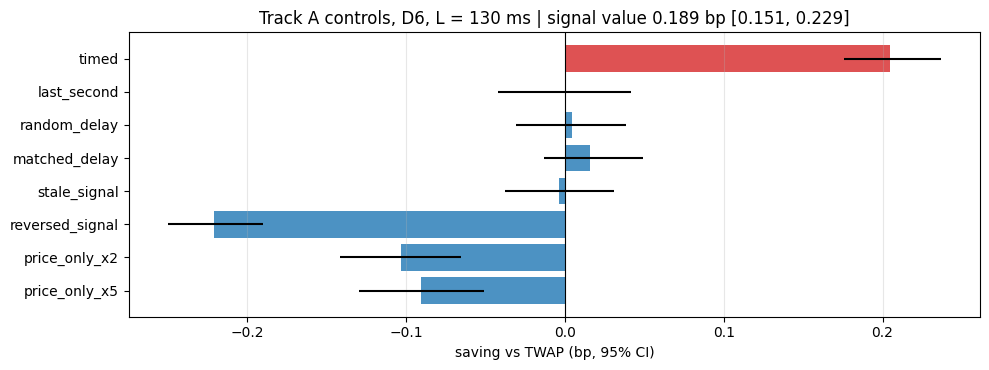

In [11]:
# selection day: every strategy at every latency (same parents as notebook 07)
st6, sd6 = valid_starts(SEL, N_PARENTS_SEL, SEED + 99); tabs6, R6 = [], {}; t0 = time.time()
for L in LAT_GRID:
    r, early = run_strategies(SEL, st6, sd6, L, SEED + 600 + L)
    r['twap'] = shortfalls(SEL, st6, sd6, child_times(SEL, st6, sd6, 'twap', L)[0], PARENT_ETH)
    tb, R6[L] = strat_table([r], f'D6 L={L}'); tb['latency_ms'] = L; tb['early_share'] = early; tabs6.append(tb)
    print(f'L={L}: done ({time.time()-t0:.0f}s)')
TA6 = pd.concat(tabs6, ignore_index=True)
rep = (R6[130]['twap'] - R6[130]['timed']).mean()
print(f'reproduction: D6 timed saving at L=130 = {rep:.4f} bp (notebook 07: {REF_TA_SAVING:.4f})' + ('' if abs(rep - REF_TA_SAVING) < 5e-3 else ' — NOT reproduced'))
display(TA6[TA6.latency_ms == 130].round(4))
piv = TA6.pivot(index='strategy', columns='latency_ms', values='saving_vs_twap_bp'); print('saving vs TWAP (bp) by latency:'); display(piv.round(4))
h6 = np.array([(pd.Timestamp(t, unit='ms').strftime('%Y-%m-%d'), pd.Timestamp(t, unit='ms').hour) for t in st6], dtype=object)
clean6 = np.array([(a, int(b)) not in BAD_HOURS and (a, int(b) + 1) not in BAD_HOURS for a, b in h6])
if (~clean6).any():
    sv = R6[130]['twap'][clean6] - R6[130]['timed'][clean6]; sg = R6[130]['matched_delay'][clean6] - R6[130]['timed'][clean6]
    print(f'excluding {int((~clean6).sum())} parents near resync hours: timed saving {sv.mean():.4f} bp, signal value {sg.mean():.4f} bp')
else: print('no D6 parent touches a resync / invalid-book hour')
TA6.to_csv(REP / '08_trackA_controls_D6.csv', index=False)
def bar(tab, title, fname):
    t = tab[~tab.strategy.str.contains('vs|VALUE') & (tab.strategy != 'twap')]; s = tab[tab.strategy.str.contains('VALUE')]
    fig, ax = plt.subplots(figsize=(10, 3.8)); y = np.arange(len(t))
    ax.barh(y, t.saving_vs_twap_bp, xerr=[t.saving_vs_twap_bp - t.ci_lo, t.ci_hi - t.saving_vs_twap_bp], color=['C3' if x == 'timed' else 'C0' for x in t.strategy], alpha=.8)
    ax.set_yticks(y); ax.set_yticklabels(t.strategy); ax.axvline(0, color='k', lw=.8); ax.invert_yaxis(); ax.grid(alpha=.3, axis='x')
    ax.set_xlabel('saving vs TWAP (bp, 95% CI)'); ax.set_title(f"{title} | signal value {s.saving_vs_twap_bp.iloc[0]:.3f} bp [{s.ci_lo.iloc[0]:.3f}, {s.ci_hi.iloc[0]:.3f}]")
    plt.tight_layout(); fig.savefig(REP / fname, dpi=110); plt.show()
bar(TA6[TA6.latency_ms == 130], 'Track A controls, D6, L = 130 ms', '08_trackA_controls_D6.png')

## 3 · Track B surface on the selection day (diagnostic)
Pessimistic queue, skew on, θ_B × latency. Gross PnL, break-even maker fee and 5 s markout. These complete notebook 07's picture; θ_B stays frozen.

In [12]:
ECOLS = ['T', 'ok', 'bp1', 'ap1', 'bq1', 'aq1', 'V_b_touch', 'V_a_touch', 'mv_b', 'mv_a', 'N_b', 'N_a']
def load_events_day(d):
    e = pd.concat([pd.read_parquet(EVT / d / f'events_{d}_{h:02d}.parquet', columns=ECOLS) for h in range(24) if (EVT / d / f'events_{d}_{h:02d}.parquet').exists()], ignore_index=True)
    return {c: e[c].to_numpy() for c in ECOLS}
def run_mm(d, E, L, theta, optimistic, q_eth=MM_Q_ETH, fee_bp=FEE_MAKER_BP):   # identical to notebook 07
    fs = rx_at(d, 'f', E['T']); fs = np.where(np.isfinite(fs), fs, 0.0)
    r = ma_lib._mm_sim(E['T'].astype(np.int64), E['ok'].astype(np.bool_), E['bp1'].astype(np.int64), E['ap1'].astype(np.int64), E['bq1'].astype(np.int64), E['aq1'].astype(np.int64),
                       E['V_b_touch'].astype(np.int64), E['V_a_touch'].astype(np.int64), E['mv_b'].astype(np.int64), E['mv_a'].astype(np.int64), E['N_b'].astype(np.int64), E['N_a'].astype(np.int64),
                       fs.astype(np.float64), int(q_eth * 1000), int(L), float(theta), int(MM_INV_MAX_ETH * 1000), bool(optimistic), theta < 1e8)
    nf = r[4]; return ma_lib.mm_results(r[0][:nf], r[1][:nf], r[2][:nf], r[3][:nf], E['T'], (E['bp1'] + E['ap1']).astype(float), fee_bp, pd.Timestamp(d).value // 10**6)
E6 = load_events_day(SEL); surf = []; t0 = time.time()
for L in LAT_GRID:
    for th in THETA_B_GRID:
        res, _ = run_mm(SEL, E6, L, th, False)
        surf.append(dict(latency_ms=L, theta_B=th, fills=res.get('fills', 0), gross_usdt=res.get('gross_ticks', 0) * 0.01, net_usdt=res.get('net_ticks', 0) * 0.01,
                         breakeven_maker_fee_bp=res.get('breakeven_maker_fee_bp', np.nan), markout_5s=res.get('markout_5s_ticks_per_eth', np.nan)))
SURF_B6 = pd.DataFrame(surf); print(f'θ_B × latency on D6 ({time.time()-t0:.0f}s), pessimistic queue:')
display(SURF_B6.pivot(index='theta_B', columns='latency_ms', values='breakeven_maker_fee_bp').round(3).rename_axis('break-even maker fee (bp)'))
display(SURF_B6.pivot(index='theta_B', columns='latency_ms', values='gross_usdt').round(1).rename_axis('gross PnL (USDT)'))
best = SURF_B6.breakeven_maker_fee_bp.max()
print(f'best break-even maker fee anywhere on the D6 surface: {best:.3f} bp (best pre-registered rebate: {min(FEE_GRID["maker"])} bp) →',
      'no configuration survives the fee grid' if best < min(FEE_GRID['maker']) else 'some configuration beats the best rebate (diagnostic: not a frozen choice)')
TB07 = pd.read_csv(REP / '07_trackB.csv'); SR_TRIALS_B = list((TB07.sharpe_daily / math.sqrt(288)).dropna())     # per-5-minute Sharpe of every D6 configuration tried
SURF_B6.to_csv(REP / '08_trackB_surface_D6.csv', index=False); del E6; _ = gc.collect()

θ_B × latency on D6 (22s), pessimistic queue:


latency_ms,0,50,130,250
break-even maker fee (bp),,,,
2.500000e-01,-1.652,-1.537,-1.460,-1.862
5.000000e-01,-1.489,-1.530,-1.527,-1.566
1.000000e+00,-1.300,-1.365,-1.350,-1.658
2.000000e+00,-0.855,-0.917,-1.095,-1.230
1.000000e+09,-0.497,-0.495,-0.491,-0.479


latency_ms,0,50,130,250
gross PnL (USDT),,,,
2.500000e-01,-433.8,-337.1,-237.8,-256.5
5.000000e-01,-472.2,-405.1,-303.5,-263.3
1.000000e+00,-486.6,-429.3,-318.7,-339.4
2.000000e+00,-465.6,-429.0,-395.6,-392.3
1.000000e+09,-966.2,-872.9,-738.6,-654.8


best break-even maker fee anywhere on the D6 surface: -0.479 bp (best pre-registered rebate: -0.5 bp) → some configuration beats the best rebate (diagnostic: not a frozen choice)


## 4 · TEST UNLOCK (D7–D8)
The next cell writes `protocol/test_unlock.json` with the time of the first unlock and the hashes of the protocol and the frozen choices. A re-run is allowed only with identical frozen choices, and the ledger records it. **From here on nothing is tuned.**

In [13]:
assert UNLOCK_TEST, 'set UNLOCK_TEST = True in the config cell to evaluate the test days'
LEDGER = PRO / 'test_unlock.json'; now = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')
if LEDGER.exists():
    led = json.loads(LEDGER.read_text(encoding='utf-8'))
    if led['frozen_choices_sha256'] != FHASH or led['protocol_sha256'] != PHASH:
        raise RuntimeError('the test days were already unlocked with DIFFERENT frozen choices or protocol; refusing to re-evaluate')
    led['reruns'].append(now); print(f"test days first unlocked {led['first_unlocked_utc']}; this is re-run #{len(led['reruns'])} with identical frozen choices")
else:
    led = dict(first_unlocked_utc=now, test_days=TEST, protocol_sha256=PHASH, frozen_choices_sha256=FHASH, reruns=[]); print('FIRST TEST UNLOCK:', now)
LEDGER.write_text(json.dumps(led, indent=2), encoding='utf-8')

FIRST TEST UNLOCK: 2026-10-11T09:58:27+00:00


312

### 4a · H1–H7 on the test days
Same estimators as notebooks 05 and 06. Anything that needs fitting (H3, H4, H5, H7) is fit on **D1–D6** (all pre-test days) and scored on D7–D8.
- Ridge and lasso penalties are the notebook-06 last-fold values.
- Hawkes parameters are the development-day medians.

One pass over the 8 days builds every dataset, so each feature grid is loaded only once.

In [14]:
hz05 = pd.read_csv(REP / '05_horizon_curve.csv'); H5_HORIZONS = [float(h) for h in hz05.loc[hz05.rw_p < 0.05, 'h_s']]
c06 = pd.read_csv(REP / '06_h5_coefs.csv'); c06 = c06[c06.test_day == DEV[-1]].set_index('h_s')
LV = [f'ofi{l}' for l in range(1, 11)]
GC = ['t_end', 'valid', 'bp1', 'ap1', 'bq1', 'aq1'] + LV + ['v_buy', 'v_sell', 'n_buy_orders', 'n_sell_orders', 'mid_changes']
def load_grid_h(d):
    g = pd.read_parquet(FEA / 'ex' / f'feat_ex_{d}.parquet', columns=GC)
    for c in GC:
        if c not in ('t_end', 'valid', 'bp1', 'ap1'): g[c] = g[c].astype(np.float32)
    return g
def batch_orders(d):                                       # taker orders at their batch's exchange time (leak guard, as in notebook 06)
    u_, T_ = [], []
    for hr in range(24):
        f = EVT / d / f'events_{d}_{hr:02d}.parquet'
        if f.exists(): e = pd.read_parquet(f, columns=['u', 'T']); u_.append(e.u.to_numpy()); T_.append(e['T'].to_numpy())
    u_, T_ = np.concatenate(u_), np.concatenate(T_)
    o = pd.read_parquet(EVT / f'taker_orders_{d}.parquet', columns=['u_post', 'sign', 'usable']); o = o[o.usable]
    j = np.clip(np.searchsorted(u_, o.u_post.to_numpy()), 0, len(u_) - 1); ok = u_[j] == o.u_post.to_numpy()
    tb = T_[j][ok]; ty = (o.sign.to_numpy()[ok] < 0).astype(np.int64); oo = np.argsort(tb, kind='stable'); return tb[oo], ty[oo]
rates = []
for d in PRE:
    g = pd.read_parquet(FEA / 'ex' / f'feat_ex_{d}.parquet', columns=['mid_changes', 'v_buy', 'v_sell'])
    rates.append((g.mid_changes.sum() / (len(g) * BIN_S), (g.v_buy + g.v_sell).sum() / 1000 / (len(g) * BIN_S)))
K_MC = max(1.0, float(np.mean([r[0] for r in rates]))); VOL_W = float(np.mean([r[1] for r in rates])); K1 = int(round(1 / BIN_S))
def h4_frame(g, d):
    co = np.cumsum(g.ofi1.to_numpy(float)) / 1000; cm_ = np.cumsum(g.mid_changes.to_numpy(float)); cv = np.cumsum((g.v_buy + g.v_sell).to_numpy(float)) / 1000
    def by(cum, w):
        s = np.searchsorted(cum, cum - w, side='right') - 1; return co - np.where(s >= 0, co[np.maximum(s, 0)], 0.0)
    wm, wv = by(cm_, K_MC), by(cv, VOL_W); b = ma_lib.bucket_grid(g, K1); end_idx = np.arange(K1 - 1, len(g) // K1 * K1, K1)
    f = pd.DataFrame({'clock': (b.ofi1 / 1000).to_numpy(), 'midchange': wm[end_idx], 'volume': wv[end_idx], 'y': b.dp_ticks.shift(-1).to_numpy()})
    m = (b.valid & b.valid.shift(-1, fill_value=False) & emb_mask(b.t_end, d)).to_numpy(); return f[m]
H3D = {h: {} for h in HORIZONS}; H4D, B1T = {}, {}; H5ACC = {h: ma_lib.GramAcc(10) for h in H5_HORIZONS}; H5P = {h: [] for h in H5_HORIZONS}; H5T = {h: {} for h in H5_HORIZONS}
t0 = time.time()
for d in PRE + TEST:
    g = load_grid_h(d); test = d in TEST
    if test:
        b1 = ma_lib.bucket_grid(g, K1); B1T[d] = b1[b1.valid][['t_end', 'dp_ticks', 'ofi1', 'v_buy', 'v_sell', 'n_buy_orders', 'n_sell_orders', 'depth_mean', 'depth_open']].copy()
    for h in HORIZONS:
        k = max(1, int(round(h / BIN_S))); b = ma_lib.bucket_grid(g, k)
        yn = b.dp_ticks.shift(-1); m = b.valid & b.valid.shift(-1, fill_value=False) & emb_mask(b.t_end, d)
        H3D[h][d] = dict(x=(b.ofi1[m] / 1000).to_numpy(), y=yn[m].to_numpy())
        if test: H3D[h][d].update(xc=(b.ofi1[b.valid] / 1000).to_numpy(), yc=b.dp_ticks[b.valid].to_numpy())
        del b
    H4D[d] = h4_frame(g, d)
    tb, ty = batch_orders(d); d0 = pd.Timestamp(d).value // 10**6
    for h in H5_HORIZONS:
        k = max(1, int(round(h / BIN_S))); b = ma_lib.bucket_levels(g, k); y = b.dp.shift(-1)
        m = (b.valid & b.valid.shift(-1, fill_value=False) & emb_mask(b.t_end, d) & np.isfinite(b.qi_end) & (b.depth_end > 0)).to_numpy()
        X = b[LV].to_numpy(np.float64)[m]; yv = y.to_numpy()[m]; tt = b.t_end.to_numpy()[m]
        Eg = ma_lib._hawkes_excitation_grid((tb - d0) / 1000.0, ty, (tt - d0) / 1000.0 + 1e-9, HK_A, HK_BETA, 2)
        part = dict(x1=X[:, 0].astype(np.float32), qi=b.qi_end.to_numpy()[m].astype(np.float32), dep=b.depth_end.to_numpy()[m].astype(np.float32), y=yv,
                    en=(Eg[:, 0] - Eg[:, 1]).astype(np.float32), et=(Eg[:, 0] + Eg[:, 1]).astype(np.float32), t=tt)
        if test: part['X'] = X.astype(np.float32); H5T[h][d] = part
        else: H5ACC[h].add(X, yv); H5P[h].append(part)
        del b, X
    del g; _ = gc.collect(); print(f'{d}: datasets built ({time.time()-t0:.0f}s)')

2026-09-07: datasets built (4s)
2026-09-08: datasets built (9s)
2026-09-09: datasets built (12s)
2026-09-10: datasets built (17s)
2026-09-11: datasets built (21s)
2026-09-12: datasets built (25s)
2026-09-13: datasets built (30s)
2026-09-14: datasets built (34s)


In [15]:
# H1 — contemporaneous CKS on 1 s buckets, each test day
res = []
for d in TEST:
    b = B1T[d]; y = b.dp_ticks.to_numpy()
    for name, x in (('OFI1', b.ofi1 / 1000), ('TI', (b.v_buy - b.v_sell) / 1000), ('signed_orders', b.n_buy_orders - b.n_sell_orders)):
        r = ma_lib.ols_hac(y, x.to_numpy(float), 6); res.append(dict(date=d, model=name, beta=r['beta'][1], t=r['t'][1], r2=r['r2']))
CKS_T = pd.DataFrame(res); r2t = CKS_T.pivot(index='date', columns='model', values='r2'); ofi = CKS_T[CKS_T.model == 'OFI1'].set_index('date')
H1T = dict(beta_positive_every_day=bool(((ofi.beta > 0) & (ofi.t > 1.96)).all()), ofi_beats_ti_days=int((r2t.OFI1 > r2t.TI).sum()))
H1T['supported'] = H1T['beta_positive_every_day'] and H1T['ofi_beats_ti_days'] == len(TEST)
display(CKS_T.round(5)); print('H1 (test):', H1T)
# H2 — depth law on pooled test buckets (same estimator as notebook 05)
Bd = pd.concat([B1T[d] for d in TEST], ignore_index=True); Bd = Bd[Bd.depth_mean > 0]
def depth_law(df, col, reps):
    dec_ = pd.qcut(df[col].rank(method='first'), 10, labels=False).to_numpy(); x = (df.ofi1 / 1000).to_numpy(float); y = df.dp_ticks.to_numpy(float)
    blk = ma_lib.block_ids(df.t_end.to_numpy(), BLOCK_MIN); ub, inv = np.unique(blk, return_inverse=True)
    S = np.zeros((len(ub), 10, 5))
    for j, w in enumerate([np.ones_like(x), x, y, x * x, x * y]): np.add.at(S[:, :, j], (inv, dec_), w)
    Dd = np.array([df[col].to_numpy()[dec_ == q].mean() for q in range(10)])
    def slope(Ss):
        n_, sx, sy, sxx, sxy = (Ss[:, j] for j in range(5)); beta = (sxy - sx * sy / n_) / (sxx - sx * sx / n_); ok = beta > 0
        return (-ma_lib.power_law_fit(Dd[ok], beta[ok])[0] if ok.sum() >= 3 else np.nan), beta
    s0, b0 = slope(S.sum(0)); rb = np.random.default_rng(SEED)
    boots = np.array([slope(S[rb.integers(0, len(ub), len(ub))].sum(0))[0] for _ in range(reps)])
    return s0, np.nanpercentile(boots, [2.5, 97.5]), Dd, b0
s_m, ci_m, D_m, b_m = depth_law(Bd, 'depth_mean', BOOT_REPS)
s_o, ci_o, _, _ = depth_law(Bd[np.isfinite(Bd.depth_open) & (Bd.depth_open > 0)], 'depth_open', BOOT_REPS)
H2T = dict(slope=round(float(s_m), 3), ci=[round(float(c), 3) for c in ci_m], ci_excludes_0=bool(ci_m[1] < 0 or ci_m[0] > 0), ci_includes_minus1=bool(ci_m[0] <= -1 <= ci_m[1]),
           slope_open=round(float(s_o), 3), ci_open=[round(float(c), 3) for c in ci_o])
H2T['supported'] = H2T['ci_excludes_0']; print('H2 (test):', H2T)

,date,model,beta,t,r2
0,2026-09-13,OFI1,0.03253,48.95973,0.42945
1,2026-09-13,TI,0.05897,6.04505,0.37235
2,2026-09-13,signed_orders,1.63832,24.64894,0.37470
3,2026-09-14,OFI1,0.03339,111.87056,0.50023
4,2026-09-14,TI,0.06898,17.71172,0.26289
5,2026-09-14,signed_orders,1.90372,49.89516,0.45917


H1 (test): {'beta_positive_every_day': True, 'ofi_beats_ti_days': 2, 'supported': True}
H2 (test): {'slope': -0.868, 'ci': [-0.946, -0.773], 'ci_excludes_0': True, 'ci_includes_minus1': False, 'slope_open': -0.32, 'ci_open': [-0.364, -0.274], 'supported': True}


In [16]:
# H3 — predictive OFI at each horizon: fit on D1–D6, score on D7–D8, permutation null + studentized Romano–Wolf
rng = np.random.default_rng(SEED); rows, NS = [], []
for h in HORIZONS:
    xtr = np.concatenate([H3D[h][d]['x'] for d in PRE]); ytr_ = np.concatenate([H3D[h][d]['y'] for d in PRE]); b0, b1 = ma_lib.ols_hac(ytr_, xtr, 0)['beta']
    parts = [(H3D[h][d]['x'], H3D[h][d]['y']) for d in TEST]; Y = np.concatenate([p[1] for p in parts]); SY2 = (Y ** 2).sum()
    r2o = 1 - sum(((y - b0 - b1 * x) ** 2).sum() for x, y in parts) / SY2
    xc = np.concatenate([H3D[h][d]['xc'] for d in TEST]); yc = np.concatenate([H3D[h][d]['yc'] for d in TEST])
    nulls = np.array([1 - sum(((y - b0 - b1 * rng.permutation(x)) ** 2).sum() for x, y in parts) / SY2 for _ in range(PERM_REPS)]); NS.append(nulls)
    rows.append(dict(h_s=h, contemp_r2=ma_lib.ols_hac(yc, xc, 0)['r2'], oos_r2=r2o, null_p95=np.percentile(nulls, 95), n_test=len(Y), beta=b1))
HZT = pd.DataFrame(rows).set_index('h_s'); NS = np.vstack(NS).T; mu, sdv = NS.mean(0), NS.std(0)
HZT['z_vs_null'] = (HZT.oos_r2.to_numpy() - mu) / sdv; HZT['rw_p'] = ma_lib.romano_wolf(HZT.z_vs_null.to_numpy(), (NS - mu) / sdv)
sig = HZT[HZT.rw_p < 0.05]
H3T = dict(supported=bool(len(sig)), significant_horizons=[float(x) for x in sig.index], peak_oos_horizon_s=float(sig.oos_r2.idxmax()) if len(sig) else None)
display(HZT.round(6)); print('H3 (test):', H3T)
# H4 — clock vs event-time windows (k and V from D1–D6), same target
TR = pd.concat([H4D[d] for d in PRE]); TE = pd.concat([H4D[d] for d in TEST]); Yt = TE.y.to_numpy(); E4 = {}
for c in ('clock', 'midchange', 'volume'):
    b0, b1 = ma_lib.ols_hac(TR.y.to_numpy(), TR[c].to_numpy(), 0)['beta']; E4[c] = (Yt - b0 - b1 * TE[c].to_numpy()) ** 2
H4TAB = pd.DataFrame({c: {'oos_r2': 1 - E4[c].sum() / (Yt ** 2).sum()} for c in E4}).T
for c in ('midchange', 'volume'):
    st_, p_, _ = ma_lib.dm_test(E4['clock'], E4[c], 6); H4TAB.loc[c, 'dm_stat_vs_clock'] = st_; H4TAB.loc[c, 'dm_p_event_better'] = p_
H4T = dict(midchange_beats_clock=bool(H4TAB.loc['midchange', 'dm_p_event_better'] < 0.05), volume_beats_clock=bool(H4TAB.loc['volume', 'dm_p_event_better'] < 0.05))
H4T['supported'] = H4T['midchange_beats_clock'] and H4T['volume_beats_clock']; display(H4TAB.round(6)); print(f'H4 (test, k = {K_MC:.2f} mid changes, V = {VOL_W:.2f} ETH):', H4T)

,contemp_r2,oos_r2,null_p95,n_test,beta,z_vs_null,rw_p
h_s,,,,,,,
0.10,0.342784,0.023027,-0.019237,1629485,0.007313,183.835391,0.000999
0.25,0.385391,0.021408,-0.014895,814736,0.006334,123.882488,0.000999
0.50,0.438700,0.018253,-0.012520,325889,0.005670,72.711223,0.000999
1.00,0.480192,0.013713,-0.009697,162940,0.004922,44.398860,0.000999
5.00,0.535866,0.004644,-0.002515,32581,0.002764,11.865010,0.000999
30.00,0.439267,0.001626,0.000566,5423,0.001231,2.823462,0.003996
120.00,0.255339,0.001186,0.001625,1350,0.000832,1.375541,0.088911


H3 (test): {'supported': True, 'significant_horizons': [0.1, 0.25, 0.5, 1.0, 5.0, 30.0], 'peak_oos_horizon_s': 0.1}


,oos_r2,dm_stat_vs_clock,dm_p_event_better
clock,0.013713,NaN,NaN
midchange,0.015075,1.930338,0.026782
volume,0.009987,-5.623766,1.000000


H4 (test, k = 1.00 mid changes, V = 40.25 ETH): {'midchange_beats_clock': True, 'volume_beats_clock': False, 'supported': False}


In [17]:
# H5 and H7 — model ladder and Hawkes features, fit on D1–D6 (sufficient statistics), scored on D7–D8
def fit_small(Z, y):
    Zc = np.c_[np.ones(len(y)), Z]; return np.linalg.solve(Zc.T @ Zc, Zc.T @ y)
lad, dm5, inc5, h7r = [], [], [], []
for h in H5_HORIZONS:
    Gs, gs, mx, sdx, ym = H5ACC[h].standardized(); n_ = H5ACC[h].n
    Pp = {k: np.concatenate([p[k] for p in H5P[h]]) for k in ('x1', 'qi', 'dep', 'y', 'en', 'et')}
    e = np.unique(np.quantile(Pp['qi'], np.linspace(0, 1, 11))); e[0], e[-1] = -np.inf, np.inf
    bt = np.digitize(Pp['qi'], e[1:-1]); cmap = np.bincount(bt, weights=Pp['y'], minlength=len(e) - 1) / np.maximum(np.bincount(bt, minlength=len(e) - 1), 1)
    Tt = {k: np.concatenate([H5T[h][d][k] for d in TEST]) for k in ('X', 'qi', 'dep', 'y', 'en', 'et', 't')}
    Ste = (Tt['X'].astype(np.float64) - mx) / sdx; yte = Tt['y']; micro_te = cmap[np.digitize(Tt['qi'], e[1:-1])]; micro_tr = cmap[bt]
    PR = {'zero': np.zeros_like(yte), 'microprice': micro_te}
    for L in range(1, 11): PR[f'levels_1_{L}'] = ym + Ste[:, :L] @ np.linalg.solve(Gs[:L, :L], gs[:L])
    a_ = float(c06.loc[h, 'ridge_alpha']) if h in c06.index else 10.0; l_ = float(c06.loc[h, 'lasso_lambda']) if h in c06.index else 1e-4
    PR['ridge'] = ym + Ste @ ma_lib.ridge_gram(Gs, gs, a_); PR['lasso'] = ym + Ste @ ma_lib.lasso_gram(Gs, gs, n_, l_)
    w = np.linalg.eigh(Gs / n_)[1][:, -1]; w = w * np.sign(w[0]); PR['integrated_pc1'] = ym + (w @ gs) / (w @ Gs @ w) * (Ste @ w)
    c = fit_small(Pp['x1'].astype(np.float64) / Pp['dep'], Pp['y']); PR['ofi1_over_depth'] = c[0] + c[1] * Tt['X'][:, 0] / Tt['dep']
    c = fit_small(np.c_[Pp['x1'], micro_tr], Pp['y']); PR['ofi1_plus_micro'] = c[0] + c[1] * Tt['X'][:, 0] + c[2] * micro_te
    E = {m: (yte - p) ** 2 for m, p in PR.items()}; SY2 = (yte ** 2).sum()
    for m in E: lad.append(dict(h_s=h, model=m, oos_r2=1 - E[m].sum() / SY2))
    for cand in ['levels_1_10', 'ridge', 'lasso', 'integrated_pc1']:
        for base in ['levels_1_1', 'microprice']:
            st_, p_, _ = ma_lib.dm_test(E[base], E[cand], 6); dm5.append(dict(h_s=h, candidate=cand, baseline=base, dm_stat=st_, p=p_))
    blk = ma_lib.block_ids(Tt['t'], BLOCK_MIN); ub, inv = np.unique(blk, return_inverse=True); SYb = np.bincount(inv, weights=yte ** 2)
    SSE = {L: np.bincount(inv, weights=E[f'levels_1_{L}']) for L in range(1, 11)}; picks = np.random.default_rng(SEED).integers(0, len(ub), (BOOT_REPS, len(ub))); keep = True
    for L in range(2, 11):
        gain = (SSE[L - 1].sum() - SSE[L].sum()) / SYb.sum(); bo = (SSE[L - 1][picks].sum(1) - SSE[L][picks].sum(1)) / SYb[picks].sum(1)
        lo, hi = np.percentile(bo, [2.5, 97.5]); keep = keep and lo > 0; inc5.append(dict(h_s=h, level=L, marginal_gain=gain, ci_lo=lo, ci_hi=hi, kept=keep))
    Ztr = np.c_[Pp['x1'], Pp['en'], Pp['et']].astype(np.float64); Zte = np.c_[Tt['X'][:, 0], Tt['en'], Tt['et']].astype(np.float64)
    cb, ca = fit_small(Ztr[:, :1], Pp['y']), fit_small(Ztr, Pp['y'])
    Eb = (yte - cb[0] - Zte[:, 0] * cb[1]) ** 2; Ea = (yte - ca[0] - Zte @ ca[1:]) ** 2; st_, p_, _ = ma_lib.dm_test(Eb, Ea, 6)
    h7r.append(dict(h_s=h, r2_ofi1=1 - Eb.sum() / SY2, r2_ofi1_hawkes=1 - Ea.sum() / SY2, dm_stat=st_, p=p_))
    del Pp, Tt, Ste, PR, E; _ = gc.collect(); print(f'h={h}s: ladder + H7 done')
LADT = pd.DataFrame(lad).pivot(index='model', columns='h_s', values='oos_r2'); DM5 = pd.DataFrame(dm5); DM5['p_holm'] = holm(DM5.p); INC5 = pd.DataFrame(inc5)
win = DM5[DM5.p_holm < 0.05].groupby(['h_s', 'candidate']).baseline.nunique()
H5T_ = dict(supported=bool((win == 2).any()), winning=[f'{c} @ {h}s' for (h, c), k_ in win.items() if k_ == 2], levels_kept={h: int(1 + INC5[(INC5.h_s == h) & INC5.kept].shape[0]) for h in H5_HORIZONS})
H7TAB = pd.DataFrame(h7r); H7TAB['p_holm'] = holm(H7TAB.p); H7TAB['gain'] = H7TAB.r2_ofi1_hawkes - H7TAB.r2_ofi1
H7T = dict(supported=bool((H7TAB.p_holm < 0.05).any()), horizons=[float(x) for x in H7TAB.h_s[H7TAB.p_holm < 0.05]])
order = ['zero', 'microprice'] + [f'levels_1_{L}' for L in range(1, 11)] + ['ridge', 'lasso', 'integrated_pc1', 'ofi1_over_depth', 'ofi1_plus_micro']
display(LADT.loc[order].round(5)); display(DM5.round(5)); print('H5 (test):', H5T_); display(H7TAB.round(6)); print('H7 (test):', H7T)

h=0.1s: ladder + H7 done
h=0.25s: ladder + H7 done
h=0.5s: ladder + H7 done
h=1.0s: ladder + H7 done
h=5.0s: ladder + H7 done
h=30.0s: ladder + H7 done


h_s,0.10,0.25,0.50,1.00,5.00,30.00
model,,,,,,
zero,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
microprice,0.02635,0.03380,0.04252,0.04565,0.03137,0.00801
levels_1_1,0.02303,0.02141,0.01825,0.01371,0.00464,0.00163
levels_1_2,0.02364,0.02145,0.01825,0.01388,0.00495,0.00160
levels_1_3,0.02412,0.02153,0.01828,0.01382,0.00495,0.00152
levels_1_4,0.02439,0.02159,0.01828,0.01378,0.00498,0.00156
levels_1_5,0.02454,0.02159,0.01822,0.01367,0.00489,0.00177
levels_1_6,0.02466,0.02159,0.01821,0.01366,0.00478,0.00081
levels_1_7,0.02474,0.02162,0.01821,0.01361,0.00476,0.00012


,h_s,candidate,baseline,dm_stat,p,p_holm
0,0.10,levels_1_10,levels_1_1,8.50792,0.00000,0.00000
1,0.10,levels_1_10,microprice,-2.37003,0.99111,1.00000
2,0.10,ridge,levels_1_1,8.50792,0.00000,0.00000
3,0.10,ridge,microprice,-2.37003,0.99111,1.00000
4,0.10,lasso,levels_1_1,8.50795,0.00000,0.00000
5,0.10,lasso,microprice,-2.37005,0.99111,1.00000
6,0.10,integrated_pc1,levels_1_1,-6.66469,1.00000,1.00000
7,0.10,integrated_pc1,microprice,-10.17729,1.00000,1.00000
8,0.25,levels_1_10,levels_1_1,2.39898,0.00822,0.36992
9,0.25,levels_1_10,microprice,-18.74016,1.00000,1.00000


H5 (test): {'supported': False, 'winning': [], 'levels_kept': {0.1: 7, 0.25: 1, 0.5: 1, 1.0: 2, 5.0: 2, 30.0: 1}}


,h_s,r2_ofi1,r2_ofi1_hawkes,dm_stat,p,p_holm,gain
0,0.10,0.023027,0.025730,5.716956,0.000000,0.000000,0.002703
1,0.25,0.021408,0.024200,5.023246,0.000000,0.000001,0.002792
2,0.50,0.018253,0.020616,3.589409,0.000166,0.000663,0.002363
3,1.00,0.013713,0.016114,2.514395,0.005962,0.017886,0.002402
4,5.00,0.004644,0.003993,-1.020546,0.846265,0.846265,-0.000651
5,30.00,0.001626,0.002612,0.532399,0.297225,0.594450,0.000986


H7 (test): {'supported': True, 'horizons': [0.1, 0.25, 0.5, 1.0]}


In [18]:
# H6 — taker-order sign memory and the propagator, each test day (same estimators as notebook 05)
lags_R = np.unique(np.round(np.logspace(0, 3, 40)).astype(int)); mem, Cs, Rs = [], [], []
for d in TEST:
    ev = pd.concat([pd.read_parquet(EVT / d / f'events_{d}_{h:02d}.parquet', columns=['u', 'bp1', 'ap1']) for h in range(24) if (EVT / d / f'events_{d}_{h:02d}.parquet').exists()], ignore_index=True)
    o = pd.read_parquet(EVT / f'taker_orders_{d}.parquet', columns=['time', 'sign', 'usable', 'u_post']); o = o[o.usable & (o.u_post >= 0)].sort_values('time', kind='stable')
    eu = ev.u.to_numpy(); m2 = (ev.bp1 + ev.ap1).to_numpy(float); i = np.clip(np.searchsorted(eu, o.u_post.to_numpy()), 1, len(eu) - 1)
    eps = o.sign.to_numpy().astype(float); mid = m2[i - 1] / 2.0
    Cf = ma_lib.acf_fft(eps, 5000); gam, _ = ma_lib.power_law_fit(np.arange(10, 1001), Cf[10:1001]); R = ma_lib.response_function(mid, eps, lags_R)
    pf = ma_lib.propagator_fit(Cf[:2001], lags_R, R, N=2000); Cs.append(Cf); Rs.append(R)
    mem.append(dict(date=d, orders=len(eps), acf_lag1=Cf[1], acf_lag100=Cf[100], gamma=gam, hurst=1 - gam / 2, G_beta=pf['beta'], G0=pf['G0']))
MEMT = pd.DataFrame(mem).set_index('date'); pooled = ma_lib.propagator_fit(np.mean(Cs, 0)[:2001], lags_R, np.nanmean(Rs, 0), N=2000)
H6T = dict(gamma_by_day=MEMT.gamma.round(3).to_dict(), kernel_beta_by_day=MEMT.G_beta.round(3).to_dict(), pooled_kernel_beta=round(pooled['beta'], 3),
           supported=bool(((MEMT.gamma > 0) & (MEMT.gamma < 1)).all() and (MEMT.G_beta > 0).all()))
display(MEMT.round(4)); print('H6 (test):', H6T)
dev_h = pd.concat([read_csv_safe(REP / '05_hypotheses.csv'), read_csv_safe(REP / '06_hypotheses.csv')], ignore_index=True).set_index('hypothesis')
HYP = pd.DataFrame([
    dict(hypothesis='H1', test_supported=H1T['supported'], test_detail=f"β>0 & t>1.96 both days: {H1T['beta_positive_every_day']}; OFI R² > TI R² on {H1T['ofi_beats_ti_days']}/{len(TEST)}; OFI R² {r2t.OFI1.round(3).tolist()} vs TI {r2t.TI.round(3).tolist()}"),
    dict(hypothesis='H2', test_supported=H2T['supported'], test_detail=f"slope {H2T['slope']} CI {H2T['ci']} (includes −1: {H2T['ci_includes_minus1']}); open-snapshot {H2T['slope_open']} CI {H2T['ci_open']}"),
    dict(hypothesis='H3', test_supported=H3T['supported'], test_detail=f"RW-significant horizons {H3T['significant_horizons']}; peak {H3T['peak_oos_horizon_s']} s; OOS R² at 0.1 s {HZT.oos_r2.iloc[0]:.4f}"),
    dict(hypothesis='H4', test_supported=H4T['supported'], test_detail=f"mid-change beats clock: {H4T['midchange_beats_clock']}; volume beats clock: {H4T['volume_beats_clock']}"),
    dict(hypothesis='H5', test_supported=H5T_['supported'], test_detail=f"winning: {H5T_['winning'] or 'none'}; levels kept {H5T_['levels_kept']}"),
    dict(hypothesis='H6', test_supported=H6T['supported'], test_detail=f"γ {H6T['gamma_by_day']}; kernel β {H6T['kernel_beta_by_day']} (pooled {H6T['pooled_kernel_beta']})"),
    dict(hypothesis='H7', test_supported=H7T['supported'], test_detail=f"significant horizons {H7T['horizons'] or 'none'}; max gain {H7TAB.gain.max():.5f}")])
HYP['dev_supported'] = HYP.hypothesis.map(lambda h: bool(dev_h.loc[h, 'supported']) if h in dev_h.index else None)
HYP['replicated'] = np.where(HYP.dev_supported == HYP.test_supported, 'same verdict', 'CHANGED')
display(HYP[['hypothesis', 'dev_supported', 'test_supported', 'replicated', 'test_detail']])
HYP.to_csv(REP / '08_hypotheses_test.csv', index=False); HZT.to_csv(REP / '08_h3_test.csv'); LADT.to_csv(REP / '08_h5_ladder_test.csv'); DM5.to_csv(REP / '08_h5_dm_test.csv', index=False)
H7TAB.to_csv(REP / '08_h7_test.csv', index=False); CKS_T.to_csv(REP / '08_h1_test.csv', index=False); MEMT.to_csv(REP / '08_h6_test.csv')
del H3D, H4D, H5ACC, H5P, H5T, B1T; _ = gc.collect()

,orders,acf_lag1,acf_lag100,gamma,hurst,G_beta,G0
date,,,,,,,
2026-09-13,493049,0.2566,0.0471,0.4389,0.7805,0.200,3.6456
2026-09-14,895640,0.2980,0.0419,0.3552,0.8224,0.175,4.5140


H6 (test): {'gamma_by_day': {'2026-09-13': 0.439, '2026-09-14': 0.355}, 'kernel_beta_by_day': {'2026-09-13': 0.2, '2026-09-14': 0.175}, 'pooled_kernel_beta': 0.175, 'supported': True}


,hypothesis,dev_supported,test_supported,replicated,test_detail
0,H1,True,True,same verdict,β>0 & t>1.96 both days: True; OFI R² > TI R² o...
1,H2,True,True,same verdict,"slope -0.868 CI [-0.946, -0.773] (includes −1:..."
2,H3,True,True,same verdict,"RW-significant horizons [0.1, 0.25, 0.5, 1.0, ..."
3,H4,False,False,same verdict,mid-change beats clock: True; volume beats clo...
4,H5,False,False,same verdict,"winning: none; levels kept {0.1: 7, 0.25: 1, 0..."
5,H6,True,True,same verdict,"γ {'2026-09-13': 0.439, '2026-09-14': 0.355}; ..."
6,H7,True,True,same verdict,"significant horizons [0.1, 0.25, 0.5, 1.0]; ma..."


### 4b · Trading signal on the test days
The frozen signal (D1–D5 fit) is scored on D7–D8: R², IC with CI, calibration, IC vs latency, future-shift placebo and shuffle null. For transparency, a **D1–D6 refit** and a **rolling walk-forward over all 8 days** are also shown (protocol: secondary, never used for choices).

,date,signal,n,r2,r2_oracle_rescaled,ic,calib_slope,calib_intercept,mean_f,mean_y,sd_f,sd_y,ic_ci_lo,ic_ci_hi
0,2026-09-13,frozen (D1–D5 fit),787635,0.02574,0.03305,0.18173,0.68243,-0.15208,0.10919,-0.07757,3.88490,14.58872,0.16441,0.19956
1,2026-09-13,refit on D1–D6 (transparency),787635,0.02867,0.03320,0.18214,0.73343,-0.15013,0.09893,-0.07757,3.62286,14.58872,0.16490,0.20016
2,2026-09-14,frozen (D1–D5 fit),840527,0.05926,0.06100,0.24697,1.20247,0.06413,-0.02382,0.03548,4.67656,22.76923,0.23079,0.26269
3,2026-09-14,refit on D1–D6 (transparency),840527,0.05780,0.06053,0.24603,1.26904,0.06583,-0.02392,0.03548,4.41422,22.76923,0.22973,0.26180


,kind,offset_ms,ic,ci_lo,ci_hi
0,past 1 s (descriptive),-1000,0.3219,0.3096,0.3342
1,latency,0,0.1723,0.1600,0.1848
2,latency,50,0.1520,0.1404,0.1644
3,latency,100,0.1520,0.1404,0.1644
4,latency,130,0.1365,0.1255,0.1484
5,latency,200,0.1365,0.1255,0.1484
6,latency,250,0.1239,0.1134,0.1352
7,latency,300,0.1239,0.1134,0.1352
8,latency,400,0.1131,0.1030,0.1239
9,latency,500,0.1042,0.0941,0.1146


test shuffle null 95th pct |IC| 0.0039 | alpha half-life (test) 750 ms


,test_day,train_days,role,r2,ic,calib_slope
0,2026-09-08,1,dev,0.05829,0.24277,1.09718
1,2026-09-09,2,dev,0.05872,0.24264,1.05392
2,2026-09-10,3,dev,0.05220,0.22850,1.00710
3,2026-09-11,4,dev,0.02378,0.15812,1.27892
4,2026-09-12,5,selection,-0.00691,0.15729,0.46925
5,2026-09-13,6,TEST,0.02867,0.18214,0.73343
6,2026-09-14,7,TEST,0.05691,0.24531,1.30332


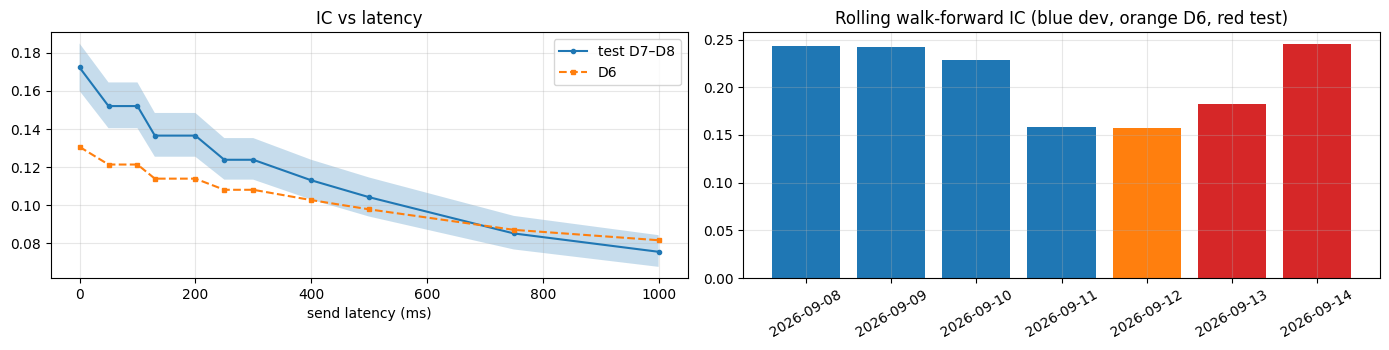

In [19]:
for d in TEST:
    RX[d] = rx_features(d); RX[d]['f'] = np.where(RX[d]['valid'], predict_sig(design(d)), np.nan)
ALL = PRE + TEST
e6, mm6 = micro_fit(PRE); acc = ma_lib.GramAcc(8)
for d in PRE:
    Z = design(d, e6, mm6)[RX[d]['mask']]; acc.add(np.c_[np.ones(len(Z)), Z], RX[d]['y'][RX[d]['mask']])
b6 = np.linalg.solve(acc.G, acc.gy)
for d in TEST: RX[d]['f_d16'] = np.where(RX[d]['valid'], b6[0] + design(d, e6, mm6) @ b6[1:], np.nan)
rows = []
for d in TEST:
    m = RX[d]['mask']; blk = ma_lib.block_ids(RX[d]['t'][m], BLOCK_MIN)
    for key, lab in (('f', 'frozen (D1–D5 fit)'), ('f_d16', 'refit on D1–D6 (transparency)')):
        c = calib(RX[d]['y'][m], RX[d][key][m]); ic, lo, hi = ma_lib.ic_ci(RX[d][key][m], RX[d]['y'][m], blk, BOOT_REPS, SEED)
        rows.append(dict(date=d, signal=lab, **c, ic_ci_lo=lo, ic_ci_hi=hi))
SIGT = pd.DataFrame(rows); display(SIGT.round(5))
IC_T = ic_table(TEST, 'f'); NULL_T = shuffle_null(TEST, 'f'); HL_T = half_life(IC_T)
display(IC_T.round(4)); print(f'test shuffle null 95th pct |IC| {NULL_T:.4f} | alpha half-life (test) {HL_T}')
wf = []
for i in range(1, len(ALL)):                                # rolling (expanding) walk-forward over all 8 days — secondary
    tr_days = ALL[:i]; e, mm = micro_fit(tr_days); a = ma_lib.GramAcc(8)
    for d in tr_days:
        Z = design(d, e, mm)[RX[d]['mask']]; a.add(np.c_[np.ones(len(Z)), Z], RX[d]['y'][RX[d]['mask']])
    bb = np.linalg.solve(a.G, a.gy); d = ALL[i]; m = RX[d]['mask']; fh = bb[0] + design(d, e, mm)[m] @ bb[1:]
    wf.append(dict(test_day=d, train_days=len(tr_days), role='dev' if d in DEV else ('selection' if d == SEL else 'TEST'), **{k: calib(RX[d]['y'][m], fh)[k] for k in ('r2', 'ic', 'calib_slope')}))
WF = pd.DataFrame(wf); display(WF.round(5))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
l = IC_T[IC_T.kind == 'latency']; ax[0].plot(l.offset_ms, l.ic, 'o-', ms=3, label='test D7–D8'); ax[0].fill_between(l.offset_ms, l.ci_lo, l.ci_hi, alpha=.25)
l6 = IC_SEL[IC_SEL.kind == 'latency']; ax[0].plot(l6.offset_ms, l6.ic, 's--', ms=3, label='D6'); ax[0].set_xlabel('send latency (ms)'); ax[0].set_title('IC vs latency'); ax[0].legend()
ax[1].bar(range(len(WF)), WF.ic, color=['C0' if r == 'dev' else ('C1' if r == 'selection' else 'C3') for r in WF.role]); ax[1].set_xticks(range(len(WF))); ax[1].set_xticklabels(WF.test_day, rotation=30)
ax[1].set_title('Rolling walk-forward IC (blue dev, orange D6, red test)')
for a_ in ax: a_.grid(alpha=.3)
plt.tight_layout(); fig.savefig(REP / '08_signal_test.png', dpi=110); plt.show()
SIGT.to_csv(REP / '08_signal_test.csv', index=False); IC_T.to_csv(REP / '08_ic_curve_test.csv', index=False); WF.to_csv(REP / '08_rolling_walkforward.csv', index=False)

### 4c · Track A on the test days
The frozen strategy (θ_A, L = 130 ms headline) and every control defined in Part 2 run on 300 new random parents per test day, at all four latencies and three sizes.

L=0: done (56s)
L=50: done (120s)
L=130: done (175s)
L=250: done (219s)


,sample,strategy,parents,shortfall_bp,saving_vs_twap_bp,ci_lo,ci_hi,positive_share,latency_ms
22,test L=130,timed,600,-0.1013,0.3391,0.3087,0.3699,0.8233,130
23,test L=130,twap,600,0.2378,0.0000,0.0000,0.0000,0.0000,130
24,test L=130,last_second,600,0.2181,0.0197,-0.0564,0.0946,0.5083,130
25,test L=130,random_delay,600,0.2413,-0.0035,-0.0652,0.0503,0.5000,130
26,test L=130,matched_delay,600,0.2163,0.0214,-0.0127,0.0574,0.5083,130
27,test L=130,stale_signal,600,0.2452,-0.0074,-0.0393,0.0228,0.4850,130
28,test L=130,reversed_signal,600,0.5725,-0.3347,-0.3699,-0.3010,0.1700,130
29,test L=130,price_only_x2,600,0.3998,-0.1620,-0.2106,-0.1141,0.3917,130
30,test L=130,price_only_x5,600,0.3952,-0.1575,-0.2081,-0.1081,0.4200,130
31,test L=130,SIGNAL VALUE (matched − timed),600,NaN,0.3177,0.2723,0.3571,0.7867,130


saving vs TWAP (bp) by latency:


latency_ms,0,50,130,250
strategy,,,,
SIGNAL VALUE (matched − timed),0.3556,0.3756,0.3177,0.3058
last_second,0.0151,0.0162,0.0197,0.0198
matched_delay,0.0177,-0.0176,0.0214,0.0075
price_only_x2,-0.1762,-0.1710,-0.1620,-0.1526
price_only_x5,-0.1715,-0.1662,-0.1575,-0.1469
random_delay,0.0301,-0.0009,-0.0035,0.0108
reversed_signal,-0.3716,-0.3580,-0.3347,-0.3122
stale_signal,-0.0069,-0.0089,-0.0074,-0.0104
timed,0.3733,0.3579,0.3391,0.3132


capacity on the test days (L = 130 ms):


,parent_eth,saving_vs_twap_bp,ci_lo,ci_hi,signal_value_bp,sv_ci_lo,sv_ci_hi
0,10,0.3416,0.3109,0.3726,0.3340,0.2921,0.3766
1,50,0.3391,0.3087,0.3699,0.3316,0.2897,0.3742
2,200,0.3269,0.2960,0.3579,0.3194,0.2779,0.3623


per test day (L = 130 ms):


,timed_saving,last_second_saving,signal_value,early_share
date,,,,
2026-09-13,0.3012,0.0479,0.2833,0.7938
2026-09-14,0.3770,-0.0085,0.3520,0.9780


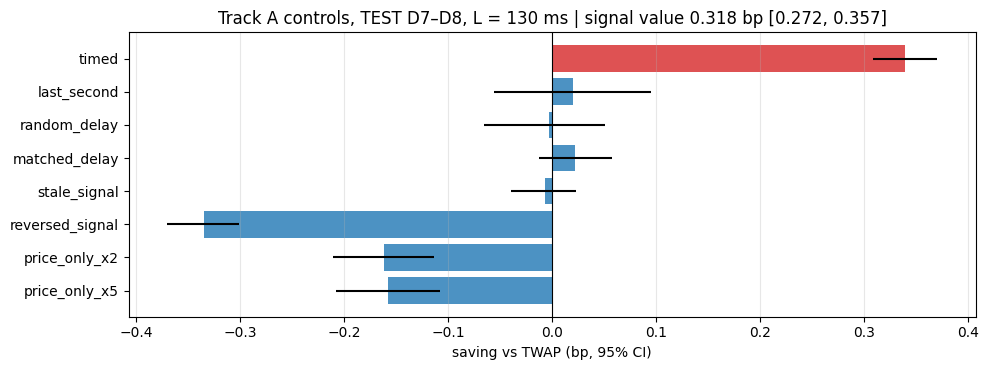

In [20]:
tabsT, RT, earlyT = [], {}, {}; t0 = time.time(); PT = {d: valid_starts(d, N_PARENTS_TEST, SEED + 300 + i) for i, d in enumerate(TEST)}
for L in LAT_GRID:
    rl = []
    for i, d in enumerate(TEST):
        st, sd = PT[d]; r, early = run_strategies(d, st, sd, L, SEED + 700 + L + i)
        r['twap'] = shortfalls(d, st, sd, child_times(d, st, sd, 'twap', L)[0], PARENT_ETH); rl.append(r); earlyT[(L, d)] = early
    tb, RT[L] = strat_table(rl, f'test L={L}'); tb['latency_ms'] = L; tabsT.append(tb); print(f'L={L}: done ({time.time()-t0:.0f}s)')
TAT = pd.concat(tabsT, ignore_index=True); display(TAT[TAT.latency_ms == 130].round(4))
print('saving vs TWAP (bp) by latency:'); display(TAT.pivot(index='strategy', columns='latency_ms', values='saving_vs_twap_bp').round(4))
capT = []
for size in (10, 50, 200):
    tw_, ti_, ma_ = [], [], []
    for i, d in enumerate(TEST):
        st, sd = PT[d]; r, _ = run_strategies(d, st, sd, 130, SEED + 800 + i, size=size, strats=['timed', 'matched_delay'])
        tw_.append(shortfalls(d, st, sd, child_times(d, st, sd, 'twap', 130)[0], size)); ti_.append(r['timed']); ma_.append(r['matched_delay'])
    tw_, ti_, ma_ = map(np.concatenate, (tw_, ti_, ma_)); lo, hi = boot_ci(tw_ - ti_); slo, shi = boot_ci(ma_ - ti_)
    capT.append(dict(parent_eth=size, saving_vs_twap_bp=(tw_ - ti_).mean(), ci_lo=lo, ci_hi=hi, signal_value_bp=(ma_ - ti_).mean(), sv_ci_lo=slo, sv_ci_hi=shi))
CAPT = pd.DataFrame(capT); print('capacity on the test days (L = 130 ms):'); display(CAPT.round(4))
n1 = len(PT[TEST[0]][0]); R130 = RT[130]
pdays = pd.DataFrame([dict(date=d, timed_saving=(R130['twap'][sl] - R130['timed'][sl]).mean(), last_second_saving=(R130['twap'][sl] - R130['last_second'][sl]).mean(),
                           signal_value=(R130['matched_delay'][sl] - R130['timed'][sl]).mean(), early_share=earlyT[(130, d)])
                      for d, sl in zip(TEST, (slice(0, n1), slice(n1, None)))]).set_index('date')
print('per test day (L = 130 ms):'); display(pdays.round(4))
TAT.to_csv(REP / '08_trackA_test.csv', index=False); CAPT.to_csv(REP / '08_trackA_capacity_test.csv', index=False)
bar(TAT[TAT.latency_ms == 130], 'Track A controls, TEST D7–D8, L = 130 ms', '08_trackA_controls_test.png')

### 4d · Track B and 4e · Track C on the test days
Frozen θ_B and the notebook-07 configuration grid, pooled over both test days. The **kill criteria** are applied to the headline configuration (L = 130 ms, pessimistic queue, skew on). The latency criterion uses the test-day alpha half-life.

In [21]:
def pool_mm(results, paths):
    s = lambda k: sum(r.get(k, 0) for r in results); q = s('eth_traded'); out = dict(fills=s('fills'), eth_traded=q)
    for k in ('gross_ticks', 'fees_ticks', 'net_ticks', 'notional_ticks', 'spread_capture_ticks', 'adverse_selection_5s_ticks', 'inventory_residual_ticks'): out[k] = s(k)
    for h in (0.1, 1, 5, 30): out[f'markout_{h}s_ticks_per_eth'] = sum(r.get(f'markout_{h}s_ticks_per_eth', 0) * r.get('eth_traded', 0) for r in results) / q if q else np.nan
    out['breakeven_maker_fee_bp'] = out['gross_ticks'] / out['notional_ticks'] * 1e4 if out['notional_ticks'] else np.nan
    p5 = np.concatenate([p.pnl5.to_numpy() for p in paths if len(p)]) if any(len(p) for p in paths) else np.zeros(1)
    cum = np.r_[0, np.cumsum(p5)]; out['max_drawdown_ticks'] = float((np.maximum.accumulate(cum) - cum).max()); out['pnl5_std_ticks'] = float(p5.std())
    out['sharpe_daily'] = float(p5.mean() / p5.std() * math.sqrt(288)) if p5.std() > 0 else np.nan; out['_p5'] = p5
    return out
EVD = {}; rowsB = []; t0 = time.time()
for L in LAT_GRID:
    for opt in (False, True):
        for th in (1e9, THETA_B):
            rr, pp = [], []
            for d in TEST:
                if d not in EVD: EVD[d] = load_events_day(d)
                r_, p_ = run_mm(d, EVD[d], L, th, opt); rr.append(r_); pp.append(p_)
            rowsB.append(dict(latency_ms=L, queue='optimistic' if opt else 'pessimistic', skew_mode='off' if th >= 1e8 else f'on (θ={th})', **pool_mm(rr, pp)))
print(f'Track B test grid done ({time.time()-t0:.0f}s)')
TBT = pd.DataFrame(rowsB); P5_HEAD = TBT[(TBT.latency_ms == 130) & (TBT.queue == 'pessimistic') & (TBT.skew_mode != 'off')]['_p5'].iloc[0]; TBT = TBT.drop(columns='_p5')
for c in [c for c in TBT.columns if c.endswith('_ticks') and 'markout' not in c]: TBT[c.replace('_ticks', '_usdt')] = TBT[c] * 0.01
show = ['latency_ms', 'queue', 'skew_mode', 'fills', 'eth_traded', 'gross_usdt', 'fees_usdt', 'net_usdt', 'spread_capture_usdt', 'adverse_selection_5s_usdt', 'breakeven_maker_fee_bp',
        'markout_1s_ticks_per_eth', 'markout_5s_ticks_per_eth', 'sharpe_daily']
display(TBT[show].round(3))
FEET = TBT[['latency_ms', 'queue', 'skew_mode', 'gross_ticks', 'notional_ticks']].copy()
for fm in FEE_GRID['maker']: FEET[f'net_usdt_maker_{fm}bp'] = (FEET.gross_ticks - fm / 1e4 * FEET.notional_ticks) * 0.01
print('net PnL (USDT, both test days) across the maker-fee grid:'); display(FEET.drop(columns=['gross_ticks', 'notional_ticks']).round(2))
HB = TBT[(TBT.latency_ms == 130) & (TBT.queue == 'pessimistic') & (TBT.skew_mode != 'off')].iloc[0]
hl_ms = float(HL_T.split()[0]) if HL_T[0].isdigit() else np.inf
KILL_T = {'max drawdown > 3 × daily PnL std': bool(HB.max_drawdown_ticks > 3 * HB.pnl5_std_ticks * math.sqrt(288)),
          '5 s markout worse than the spread captured (markout_5s < 0)': bool(HB['markout_5s_ticks_per_eth'] < 0),
          f'alpha half-life ({HL_T}) shorter than the send latency (130 ms)': bool(hl_ms < 130)}
print('kill criteria, headline Track B on the test days:'); [print(('TRIGGERED  ' if v else 'ok         ') + k) for k, v in KILL_T.items()]
TBT.to_csv(REP / '08_trackB_test.csv', index=False); FEET.to_csv(REP / '08_trackB_fee_grid_test.csv', index=False)
# Track C
mid_t = np.nanmedian(np.concatenate([(EVD[d]['bp1'] + EVD[d]['ap1']) / 2 for d in TEST]))      # ticks
fT = np.concatenate([RX[d]['f'][np.isfinite(RX[d]['f'])] for d in TEST])
TCT = pd.DataFrame([dict(taker_fee_bp=ft, round_trip_cost_ticks=2 * ft / 1e4 * mid_t + 1, max_abs_forecast_ticks=np.abs(fT).max(), p99_abs_forecast_ticks=np.percentile(np.abs(fT), 99),
                         bins_exceeding=int((np.abs(fT) > 2 * ft / 1e4 * mid_t + 1).sum())) for ft in FEE_GRID['taker']])
display(TCT.round(3)); print('Track C trades on the test days:', int(TCT.bins_exceeding.max())); TCT.to_csv(REP / '08_trackC_test.csv', index=False)
del EVD; _ = gc.collect()

Track B test grid done (23s)


,latency_ms,queue,skew_mode,fills,eth_traded,gross_usdt,fees_usdt,net_usdt,spread_capture_usdt,adverse_selection_5s_usdt,breakeven_maker_fee_bp,markout_1s_ticks_per_eth,markout_5s_ticks_per_eth,sharpe_daily
0,0,pessimistic,off,48846,43652.555,-10251.922,21933.607,-32185.529,-4779.540,-5256.603,-0.935,-20.685,-22.991,-16.459
1,0,pessimistic,on (θ=1.0),10133,9791.448,-2252.241,4924.743,-7176.984,-1385.788,-1217.068,-0.915,-25.441,-26.583,-6.445
2,0,optimistic,off,82903,60393.286,-11151.689,30344.990,-41496.679,-4501.316,-6358.780,-0.735,-15.617,-17.982,-18.208
3,0,optimistic,on (θ=1.0),12096,11349.777,-2468.784,5707.966,-8176.750,-1348.446,-1274.699,-0.865,-22.255,-23.112,-6.992
4,50,pessimistic,off,42994,38739.958,-9229.028,19462.488,-28691.516,-4369.658,-4783.429,-0.948,-20.958,-23.627,-16.626
5,50,pessimistic,on (θ=1.0),8290,8059.891,-2083.249,4052.875,-6136.124,-1193.349,-969.257,-1.028,-25.608,-26.832,-6.285
6,50,optimistic,off,75685,54880.255,-10027.381,27571.561,-37598.942,-4083.146,-5801.213,-0.727,-15.519,-18.011,-18.506
7,50,optimistic,on (θ=1.0),10153,9515.901,-2099.660,4784.747,-6884.408,-1157.296,-1072.711,-0.878,-22.233,-23.435,-6.706
8,130,pessimistic,off,36029,32592.684,-7584.800,16373.054,-23957.854,-3733.085,-3851.388,-0.926,-20.773,-23.270,-17.061
9,130,pessimistic,on (θ=1.0),5929,5799.533,-1327.356,2915.214,-4242.570,-910.028,-610.607,-0.911,-25.962,-26.220,-5.481


net PnL (USDT, both test days) across the maker-fee grid:


,latency_ms,queue,skew_mode,net_usdt_maker_-0.5bp,net_usdt_maker_0.0bp,net_usdt_maker_1.0bp,net_usdt_maker_2.0bp
0,0,pessimistic,off,-4768.52,-10251.92,-21218.73,-32185.53
1,0,pessimistic,on (θ=1.0),-1021.05,-2252.24,-4714.61,-7176.98
2,0,optimistic,off,-3565.44,-11151.69,-26324.18,-41496.68
3,0,optimistic,on (θ=1.0),-1041.79,-2468.78,-5322.77,-8176.75
4,50,pessimistic,off,-4363.41,-9229.03,-18960.27,-28691.52
5,50,pessimistic,on (θ=1.0),-1070.03,-2083.25,-4109.69,-6136.12
6,50,optimistic,off,-3134.49,-10027.38,-23813.16,-37598.94
7,50,optimistic,on (θ=1.0),-903.47,-2099.66,-4492.03,-6884.41
8,130,pessimistic,off,-3491.54,-7584.80,-15771.33,-23957.85
9,130,pessimistic,on (θ=1.0),-598.55,-1327.36,-2784.96,-4242.57


kill criteria, headline Track B on the test days:
TRIGGERED  max drawdown > 3 × daily PnL std
TRIGGERED  5 s markout worse than the spread captured (markout_5s < 0)
ok         alpha half-life (750 ms) shorter than the send latency (130 ms)


,taker_fee_bp,round_trip_cost_ticks,max_abs_forecast_ticks,p99_abs_forecast_ticks,bins_exceeding
0,2.5,126.595,65.763,11.648,0
1,4.0,201.952,65.763,11.648,0
2,5.0,252.190,65.763,11.648,0


Track C trades on the test days: 0


## 5 · Sensitivity surfaces and deflated Sharpe
- **Track A, θ × latency** on D6 and on the test days. The test-day surface is a diagnostic: it shows whether the frozen θ was near the best region, never a re-choice. It shows both the saving vs TWAP and the signal value vs matched delay.
- **Track B, maker fee × latency** on the test days, for the four configurations.
- **Deflated Sharpe ratio:**
  - **Track A:** the test-day per-parent savings, deflated for the 5 timed θ values tried in notebook 07, with the trials' Sharpe variance taken from the development days.
  - **Track B:** the test-day 5-minute PnL of the headline configuration, deflated for the 16 D6 configurations of notebook 07.
  - **Signal value:** this involved no selection, so it gets a plain probabilistic Sharpe ratio (PSR) against 0.

θ × latency surfaces (321s)


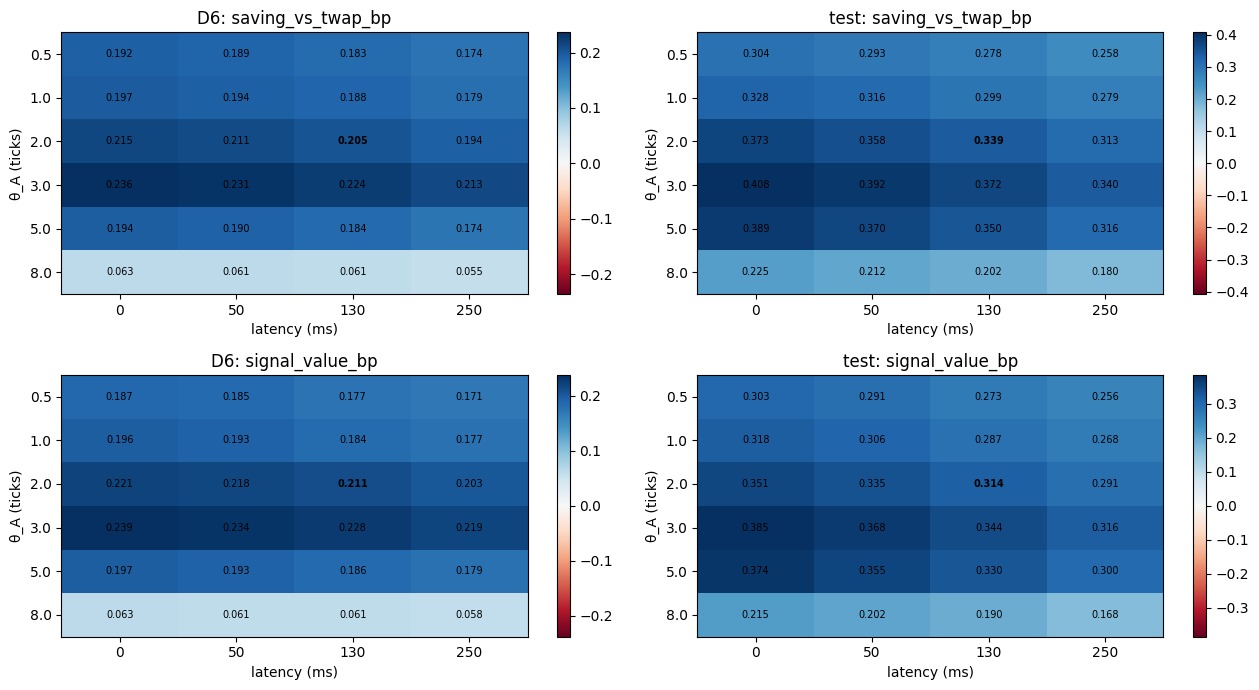

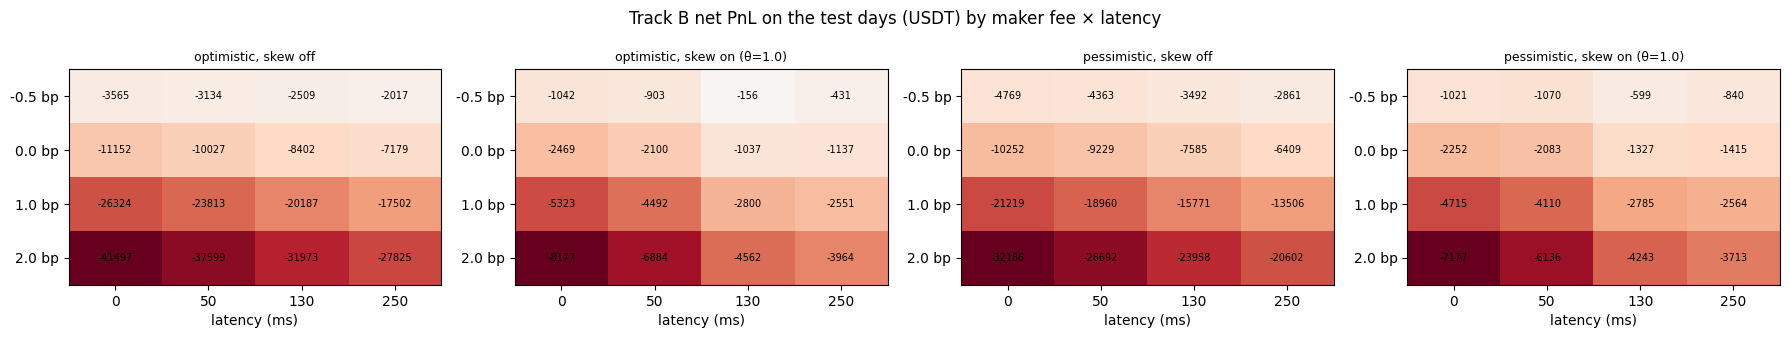

deflated Sharpe (per-observation Sharpe; dsr = probability the true Sharpe exceeds the deflation benchmark sr0):


,item,sr,sr0,n_trials,dsr
0,"Track A saving (test, per parent)",0.8708,0.0289,5,1.0
1,"Track A signal value (test, per parent; no sel...",0.6349,0.0000,0,1.0
2,"Track B headline (test, per 5 min)",-0.3230,0.7897,16,0.0


In [22]:
TH_SURF = [0.5, 1.0, 2.0, 3.0, 5.0, 8.0]
def theta_surface(days_parents, label, seed0):
    rows = []
    for L in LAT_GRID:
        tw = {d: shortfalls(d, st, sd, child_times(d, st, sd, 'twap', L)[0], PARENT_ETH) for d, (st, sd) in days_parents.items()}
        for th in TH_SURF:
            sv, sg = [], []
            for i, (d, (st, sd)) in enumerate(days_parents.items()):
                r, _ = run_strategies(d, st, sd, L, seed0 + i, theta=th, strats=['timed', 'matched_delay']); sv.append(tw[d] - r['timed']); sg.append(r['matched_delay'] - r['timed'])
            rows.append(dict(sample=label, latency_ms=L, theta=th, saving_vs_twap_bp=np.concatenate(sv).mean(), signal_value_bp=np.concatenate(sg).mean()))
    return pd.DataFrame(rows)
t0 = time.time(); SA6 = theta_surface({SEL: (st6, sd6)}, 'D6', SEED + 900); SAT = theta_surface(PT, 'test (diagnostic)', SEED + 950); print(f'θ × latency surfaces ({time.time()-t0:.0f}s)')
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for j, (S, lab) in enumerate(((SA6, 'D6'), (SAT, 'test'))):
    for i, col in enumerate(('saving_vs_twap_bp', 'signal_value_bp')):
        M = S.pivot(index='theta', columns='latency_ms', values=col); v = np.nanmax(np.abs(M.to_numpy()))
        im = ax[i, j].imshow(M.to_numpy(), cmap='RdBu', vmin=-v, vmax=v, aspect='auto'); ax[i, j].set_xticks(range(M.shape[1])); ax[i, j].set_xticklabels(M.columns)
        ax[i, j].set_yticks(range(M.shape[0])); ax[i, j].set_yticklabels(M.index); ax[i, j].set_xlabel('latency (ms)'); ax[i, j].set_ylabel('θ_A (ticks)')
        for a_ in range(M.shape[0]):
            for b_ in range(M.shape[1]): ax[i, j].text(b_, a_, f'{M.iloc[a_, b_]:.3f}', ha='center', va='center', fontsize=7, fontweight='bold' if M.index[a_] == THETA_A and M.columns[b_] == 130 else None)
        ax[i, j].set_title(f'{lab}: {col}'); plt.colorbar(im, ax=ax[i, j])
plt.tight_layout(); fig.savefig(REP / '08_trackA_surfaces.png', dpi=110); plt.show()
fig, ax = plt.subplots(1, 4, figsize=(18, 3.4)); fcols = [f'net_usdt_maker_{fm}bp' for fm in FEE_GRID['maker']]
for k, ((q, s), grp) in enumerate(FEET.groupby(['queue', 'skew_mode'])):
    M = grp.set_index('latency_ms')[fcols].T; v = np.nanmax(np.abs(M.to_numpy()))
    im = ax[k].imshow(M.to_numpy(), cmap='RdBu', vmin=-v, vmax=v, aspect='auto'); ax[k].set_xticks(range(M.shape[1])); ax[k].set_xticklabels(M.columns); ax[k].set_yticks(range(len(fcols)))
    ax[k].set_yticklabels([f'{fm} bp' for fm in FEE_GRID['maker']]); ax[k].set_title(f'{q}, skew {s}', fontsize=9); ax[k].set_xlabel('latency (ms)')
    for a_ in range(M.shape[0]):
        for b_ in range(M.shape[1]): ax[k].text(b_, a_, f'{M.iloc[a_, b_]:.0f}', ha='center', va='center', fontsize=7)
fig.suptitle('Track B net PnL on the test days (USDT) by maker fee × latency'); plt.tight_layout(); fig.savefig(REP / '08_trackB_fee_latency_test.png', dpi=110); plt.show()
svA = R130['twap'] - R130['timed']; sig_v = R130['matched_delay'] - R130['timed']
DSR = pd.DataFrame([dict(item='Track A saving (test, per parent)', **ma_lib.deflated_sharpe(svA, SR_TRIALS_A)),
                    dict(item='Track A signal value (test, per parent; no selection)', **ma_lib.deflated_sharpe(sig_v, [])),
                    dict(item='Track B headline (test, per 5 min)', **ma_lib.deflated_sharpe(P5_HEAD, SR_TRIALS_B))])
print('deflated Sharpe (per-observation Sharpe; dsr = probability the true Sharpe exceeds the deflation benchmark sr0):'); display(DSR.round(4))
pd.concat([SA6, SAT]).to_csv(REP / '08_trackA_theta_latency.csv', index=False); DSR.to_csv(REP / '08_deflated_sharpe.csv', index=False)

## 6 · Scorecard and summary

In [23]:
ic0 = lambda tab: tab[tab.offset_ms == 0].iloc[0]
a6 = TA6[(TA6.latency_ms == 130)].set_index('strategy'); at = TAT[(TAT.latency_ms == 130)].set_index('strategy'); dv = TDEV.set_index('strategy')
fmt = lambda r: f"{r.saving_vs_twap_bp:.3f} [{r.ci_lo:.3f}, {r.ci_hi:.3f}]"
b6 = TB07[(TB07.latency_ms == 130) & (TB07.queue == 'pessimistic') & (TB07.skew_mode != 'off')].iloc[0]
SC = pd.DataFrame([
    dict(claim='Signal OOS R² (1 s, received clock)', dev=f"LODO mean {LODO[(LODO.variant == 'full') & LODO.date.isin(DEV)].r2.mean():.4f}", selection_D6=f"{CAL.loc[SEL].r2:.4f}", test=' / '.join(f'{x:.4f}' for x in SIGT[SIGT.signal.str.startswith('frozen')].r2)),
    dict(claim='Signal IC (1 s, L = 0)', dev=f"{ic0(IC_DEV).ic:.3f}", selection_D6=f"{ic0(IC_SEL).ic:.3f}", test=f"{ic0(IC_T).ic:.3f} [{ic0(IC_T).ci_lo:.3f}, {ic0(IC_T).ci_hi:.3f}]"),
    dict(claim='Alpha half-life', dev=HL_DEV, selection_D6=HL_SEL, test=HL_T),
    dict(claim='Track A saving vs TWAP, bp (L=130)', dev=fmt(dv.loc['timed']), selection_D6=fmt(a6.loc['timed']), test=fmt(at.loc['timed'])),
    dict(claim='Track A last-second saving (delay only)', dev=fmt(dv.loc['last_second']), selection_D6=fmt(a6.loc['last_second']), test=fmt(at.loc['last_second'])),
    dict(claim='Track A SIGNAL VALUE (matched − timed)', dev=fmt(dv.loc['SIGNAL VALUE (matched − timed)']), selection_D6=fmt(a6.loc['SIGNAL VALUE (matched − timed)']), test=fmt(at.loc['SIGNAL VALUE (matched − timed)'])),
    dict(claim='Track B break-even maker fee, bp (headline)', dev='—', selection_D6=f"{b6.breakeven_maker_fee_bp:.3f}", test=f"{HB.breakeven_maker_fee_bp:.3f}"),
    dict(claim='Track B net USDT at headline fee', dev='—', selection_D6=f"{b6.net_usdt:.1f}", test=f"{HB.net_usdt:.1f}"),
    dict(claim='Track C trades', dev='—', selection_D6='0', test=str(int(TCT.bins_exceeding.max())))] +
    [dict(claim=f'{r.hypothesis}', dev='supported' if r.dev_supported else 'not supported', selection_D6='—', test=('supported' if r.test_supported else 'not supported') + f' ({r.replicated})') for r in HYP.itertuples()])
display(SC); SC.to_csv(REP / '08_scorecard.csv', index=False)
sv_t = at.loc['SIGNAL VALUE (matched − timed)']
verdict_A = ('the OFI signal adds value beyond timing (signal-value CI excludes 0 on the test days)' if sv_t.ci_lo > 0 else
             'the Track A saving is NOT attributable to the signal on the test days (signal-value CI includes or is below 0)')
lines = ['# 08 · Robustness, controls and the one-time test unlock', '', f"protocol sha256 {PHASH}; frozen choices sha256 {FHASH}; test unlock ledger: {LEDGER.name} (first unlock {led['first_unlocked_utc']}, re-runs {len(led['reruns'])})", '',
         f"signal diagnostics (pre-unlock): D6 R² {CAL.loc[SEL].r2:.4f} with IC {CAL.loc[SEL].ic:.3f} and calibration slope {CAL.loc[SEL].calib_slope:.2f} → {diag}; condition number {COND:.1f}; "
         f"VIF qi {VIF[3]:.1f}, micro {VIF[6]:.1f}; half-life D6 {HL_SEL}",
         f"Track A pre-unlock (D6, L=130): timed {fmt(a6.loc['timed'])}; last-second {fmt(a6.loc['last_second'])}; matched delay {fmt(a6.loc['matched_delay'])}; signal value {fmt(a6.loc['SIGNAL VALUE (matched − timed)'])}",
         f"θ_A extended grid (dev, diagnostic): {cm.round(3).to_dict()}; LODO θ choices {FOLD.theta_chosen.tolist()}", '',
         'TEST (D7–D8):'] + [f"  {r.hypothesis}: dev {'S' if r.dev_supported else 'NS'} → test {'SUPPORTED' if r.test_supported else 'NOT SUPPORTED'} ({r.replicated}) — {r.test_detail}" for r in HYP.itertuples()] + [
         f"  signal (frozen): R² {SIGT[SIGT.signal.str.startswith('frozen')].r2.round(4).tolist()}, IC {SIGT[SIGT.signal.str.startswith('frozen')].ic.round(3).tolist()}, half-life {HL_T}",
         f"  Track A (L=130): timed {fmt(at.loc['timed'])}; last-second {fmt(at.loc['last_second'])}; signal value {fmt(sv_t)} → {verdict_A}",
         f"  Track A by latency (timed vs TWAP): " + '; '.join(f"L={L}: {TAT[(TAT.latency_ms == L) & (TAT.strategy == 'timed')].saving_vs_twap_bp.iloc[0]:.3f}" for L in LAT_GRID),
         f"  Track B headline: net {HB.net_usdt:.1f} USDT at {FEE_MAKER_BP} bp, break-even {HB.breakeven_maker_fee_bp:.3f} bp, 5 s markout {HB['markout_5s_ticks_per_eth']:.2f} ticks/ETH; kill: {[k for k, v in KILL_T.items() if v] or 'none'}",
         f"  Track C trades: {int(TCT.bins_exceeding.max())}",
         '  deflated Sharpe: ' + '; '.join(f"{r.item}: SR {r.sr:.4f}, sr0 {r.sr0:.4f}, DSR {r.dsr:.3f}" for r in DSR.itertuples()),
         'Funding not modelled (no funding-rate data); holding periods are sub-hour.']
(REP / '08_summary.md').write_text('\n'.join(lines), encoding='utf-8'); print('\n'.join(lines))
print('\nSend me: reports/08_summary.md, 08_scorecard.csv, 08_hypotheses_test.csv, 08_signal_calibration.csv, 08_signal_lodo.csv, 08_ic_curve_pretest.csv, 08_ic_curve_test.csv, '
      '08_signal_test.csv, 08_rolling_walkforward.csv, 08_trackA_controls_dev.csv, 08_trackA_controls_D6.csv, 08_trackA_test.csv, 08_trackA_capacity_test.csv, 08_trackA_calibration_ext.csv, '
      '08_trackA_theta_latency.csv, 08_trackB_surface_D6.csv, 08_trackB_test.csv, 08_trackB_fee_grid_test.csv, 08_deflated_sharpe.csv and the PNGs')

,claim,dev,selection_D6,test
0,"Signal OOS R² (1 s, received clock)",LODO mean 0.0494,-0.0069,0.0257 / 0.0593
1,"Signal IC (1 s, L = 0)",0.151,0.131,"0.172 [0.160, 0.185]"
2,Alpha half-life,750 ms,"> 1000 ms (IC(1 s)/IC(0) = 0.63, CI 0.56–0.69)",750 ms
3,"Track A saving vs TWAP, bp (L=130)","0.338 [0.299, 0.382]","0.205 [0.176, 0.237]","0.339 [0.309, 0.370]"
4,Track A last-second saving (delay only),"0.049 [-0.064, 0.156]","0.000 [-0.042, 0.041]","0.020 [-0.056, 0.095]"
5,Track A SIGNAL VALUE (matched − timed),"0.370 [0.306, 0.433]","0.189 [0.151, 0.229]","0.318 [0.272, 0.357]"
6,"Track B break-even maker fee, bp (headline)",—,-1.350,-0.911
7,Track B net USDT at headline fee,—,-790.6,-4242.6
8,Track C trades,—,0,0
9,H1,supported,—,supported (same verdict)


# 08 · Robustness, controls and the one-time test unlock

protocol sha256 0224381a70665d880a38c72f35f2b250fa3c97b7281b56e817d71372b22234af; frozen choices sha256 c540fa09a5111069488bcebca00cae46a03d591ffce33a93abac819a22ab762e; test unlock ledger: test_unlock.json (first unlock 2026-10-11T09:58:27+00:00, re-runs 0)

signal diagnostics (pre-unlock): D6 R² -0.0069 with IC 0.157 and calibration slope 0.47 → ranking information is intact (IC > 0) but the forecast is mis-scaled: slope 0.47 (1 = well scaled), intercept 0.0036 ticks; condition number 45.2; VIF qi 9.5, micro 9.6; half-life D6 > 1000 ms (IC(1 s)/IC(0) = 0.63, CI 0.56–0.69)
Track A pre-unlock (D6, L=130): timed 0.205 [0.176, 0.237]; last-second 0.000 [-0.042, 0.041]; matched delay 0.016 [-0.013, 0.049]; signal value 0.189 [0.151, 0.229]
θ_A extended grid (dev, diagnostic): {0.1: 0.243, 0.25: 0.249, 0.5: 0.267, 1.0: 0.287, 2.0: 0.338, 3.0: 0.344, 5.0: 0.375, 8.0: 0.174, 13.0: 0.098}; LODO θ choices [2.0, 2.0, 2.0, 2.0, 2.0]

TEST